<a href="https://colab.research.google.com/github/renatoruiz2607/fiapCursoTecIA/blob/dev/fase6/cap1/fiapAgroNeuralNetwork/RenatoRuiz_rm572235_pbl_fase6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Este projeto tem como objetivo implementar e comparar três abordagens de visão computacional: YOLO adaptável, YOLO padrão e uma Rede Neural Convolucional (CNN) treinada do zero, analisando suas diferenças de funcionamento, desempenho e custo computacional.*

*Para os experimentos, será utilizado um conjunto de 94 imagens de dois objetos: um controle de PlayStation 5 e uma garrafa térmica. As imagens foram capturadas em diferentes condições e organizadas em conjuntos de treinamento, validação e teste, permitindo avaliar o comportamento dos modelos diante de dados não utilizados durante o treinamento.*

*O desenvolvimento será dividido em três abordagens:*

****YOLO adaptável***: utilizar o YOLOv5 com pesos pré-treinados e realizar um treinamento personalizado para reconhecer os dois objetos, comparando os resultados obtidos com 30 e 60 épocas.*

****YOLO padrão***: executar o YOLOv5 com os pesos originais do dataset COCO, sem treinamento adicional, para avaliar sua capacidade de reconhecer os objetos sem adaptação ao conjunto de imagens.*

****CNN treinada do zero***: desenvolver uma rede neural convolucional utilizando TensorFlow/Keras, com pesos inicializados aleatoriamente, para classificar as imagens entre as duas categorias.*

*Ao longo dos experimentos, serão analisadas métricas como precisão, recall, acurácia, mAP e F1-score, conforme a finalidade de cada arquitetura. Também serão registrados os tempos de treinamento e inferência, além das dificuldades e particularidades de implementação.*

*A comparação busca compreender como a personalização de modelos, o uso de pesos pré-treinados e a construção de uma rede neural do zero influenciam os resultados obtidos. Também pretende demonstrar as diferenças entre detecção de objetos e classificação de imagens, considerando que essas tarefas possuem objetivos e métricas de avaliação distintos.*

*Ao final, espera-se identificar as vantagens, limitações e aplicações mais adequadas de cada abordagem, relacionando a qualidade dos resultados ao esforço de implementação e aos recursos computacionais necessários.*

### ***- Entrega 1 ----------------------------------------***

### Estabelecendo conexão com o Drive

In [1]:

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


### Instalando YOLOv5

In [2]:

%cd /content

!git clone https://github.com/ultralytics/yolov5.git
%pip install -r /content/yolov5/requirements.txt

/content
Cloning into 'yolov5'...
remote: Enumerating objects: 18770, done.
remote: Counting objects: 100% (326/326), done.
remote: Compressing objects: 100% (192/192), done.
remote: Total 18770 (delta 263), reused 134 (delta 134), pack-reused 18444 (from 5)
Receiving objects: 100% (18770/18770), 17.80 MiB | 20.12 MiB/s, done.
Resolving deltas: 100% (12766/12766), done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 9.9 MB/s eta 0:00:00


### Verificando a GPU

In [35]:

import torch

# Verifica se há uma GPU compatível com CUDA disponível para acelerar o treinamento e a inferência dos modelos.
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    # Identifica a GPU que será utilizada nos experimentos.
    print("GPU:", torch.cuda.get_device_name(0))


CUDA disponível: True
GPU: Tesla T4


### Validando o Dataset

In [4]:

from pathlib import Path

# Define o caminho do dataset armazenado no Google Drive.
DATASET = Path('/content/drive/MyDrive/dataset')

# Verifica se o diretório existe e está acessível no ambiente do Colab.
print("Dataset encontrado:", DATASET.exists())


Dataset encontrado: True


### Verificando se cada imagem possui sua anotação (arquivo .txt gerado no Make Sense) correspondente

In [5]:

# Define os formatos de imagem aceitos no dataset.
extensoes = {'.jpg', '.jpeg', '.png'}

# Verifica a quantidade de imagens e anotações em cada conjunto do dataset.
for conjunto in ['train', 'val', 'test']:
    pasta_imagens = DATASET / 'images' / conjunto
    pasta_labels = DATASET / 'labels' / conjunto

    # Lista as imagens com extensões válidas.
    imagens = [
        p for p in pasta_imagens.iterdir()
        if p.suffix.lower() in extensoes
    ]

    # Identifica os arquivos de anotação gerados no Make Sense.
    anotacoes = list(pasta_labels.glob('*.txt'))

    # Verifica se todas as imagens possuem um arquivo de anotação correspondente.
    sem_anotacao = [
        p.name for p in imagens
        if not (pasta_labels / f'{p.stem}.txt').exists()
    ]

    # Apresenta o resumo de cada conjunto e possíveis anotações ausentes.
    print(f'\n{conjunto.upper()}')
    print('Imagens:', len(imagens))
    print('Anotações:', len(anotacoes))
    print('Sem anotação:', sem_anotacao)



TRAIN
Imagens: 74
Anotações: 74
Sem anotação: []

VAL
Imagens: 10
Anotações: 10
Sem anotação: []

TEST
Imagens: 10
Anotações: 10
Sem anotação: []


### Validando as classes e coordenadas

*Esta etapa tem como objetivo verificar a integridade das anotações geradas no Make Sense, garantindo que os arquivos estejam no formato esperado pelo YOLO. São validados os identificadores das classes, os limites das coordenadas normalizadas e as dimensões das caixas delimitadoras (bounding boxes).*

*Essa verificação permite identificar possíveis inconsistências antes do treinamento, evitando erros de processamento e garantindo que o modelo utilize anotações válidas para aprender a localizar e reconhecer os objetos.*

In [6]:

# Inicializa a lista de erros e a contagem de objetos anotados por classe.
erros = []
contagem = {0: 0, 1: 0}

# Percorre os arquivos de anotação dos conjuntos de treinamento, validação e teste.
for conjunto in ['train', 'val', 'test']:
    pasta = DATASET / 'labels' / conjunto

    for arquivo in pasta.glob('*.txt'):
        for numero, linha in enumerate(
            arquivo.read_text().splitlines(), start=1
        ):
            valores = linha.split()

            try:
                # Valida o formato YOLO: classe e quatro coordenadas.
                assert len(valores) == 5

                classe = int(valores[0])
                coordenadas = [float(v) for v in valores[1:]]

                # Verifica as classes permitidas e os limites das coordenadas normalizadas.
                assert classe in (0, 1)
                assert all(0 <= v <= 1 for v in coordenadas)

                # Garante que a largura e a altura das caixas sejam maiores que zero.
                assert coordenadas[2] > 0
                assert coordenadas[3] > 0

                contagem[classe] += 1

            except (ValueError, AssertionError):
                # Registra o arquivo e a linha que apresentam inconsistências.
                erros.append(f'{arquivo.name}, linha {numero}')

# Apresenta a quantidade de objetos por classe e possíveis erros nas anotações.
print('Objetos anotados por classe:', contagem)
print('Erros encontrados:', erros)


Objetos anotados por classe: {0: 48, 1: 48}
Erros encontrados: []


### Criando o arquivo dataset.yaml

*Nesta etapa, criamos o arquivo dataset.yaml, responsável por informar ao YOLO a localização das imagens de treinamento, validação e teste, além da quantidade de classes e seus respectivos nomes.*

*Esse arquivo permite que o modelo interprete corretamente a estrutura do dataset e associe os identificadores numéricos das anotações aos objetos que serão reconhecidos durante o treinamento e a avaliação.*

In [ ]:

import yaml

# Define a estrutura do dataset e os caminhos dos conjuntos de imagens.
configuracao = {
    'path': str(DATASET),
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',

    # Informa a quantidade de classes e seus identificadores.
    'nc': 2,
    'names': {
        0: 'controle_ps5',
        1: 'garrafa_termica'
    }
}

# Cria o arquivo de configuração YAML na pasta principal do dataset.
with open(DATASET / 'dataset.yaml', 'w') as arquivo:
    yaml.safe_dump(
        configuracao,
        arquivo,
        sort_keys=False,      # Preserva a ordem dos campos.
        allow_unicode=True    # Permite caracteres especiais.
    )

# Confirma a criação do arquivo de configuração.
print('Arquivo dataset.yaml criado com sucesso!')


Arquivo dataset.yaml criado com sucesso!


### Treinando YOLO adaptável com 30 épocas

*Nesta etapa, realizamos o primeiro treinamento do YOLO adaptável, utilizando o modelo YOLOv5s com pesos pré-treinados e o dataset personalizado de controle PS5 e garrafa térmica.*

*O treinamento será realizado durante 30 épocas, permitindo que o modelo ajuste seus parâmetros para reconhecer e localizar os objetos definidos no projeto. Também será registrado o tempo total de treinamento, que será utilizado posteriormente na comparação com o modelo de 60 épocas e com a CNN treinada do zero.*

*Os resultados, incluindo os pesos do modelo treinado e as métricas de desempenho, serão armazenados no Google Drive para análise posterior.*

In [8]:

import time

# Inicia a contagem do tempo total de treinamento.
inicio_30 = time.perf_counter()

# Executa o treinamento do YOLOv5s com o dataset personalizado.
!python /content/yolov5/train.py \
  --data /content/drive/MyDrive/dataset/dataset.yaml \
  --weights yolov5s.pt \
  --img 640 \
  --batch 8 \
  --epochs 30 \
  --device 0 \
  --project /content/drive/MyDrive/YOLO_Resultados \
  --name treino_30 \
  --exist-ok

# Calcula o tempo decorrido após a conclusão do treinamento.
tempo_30 = time.perf_counter() - inicio_30

# Apresenta o tempo total em segundos e minutos.
print(f"Tempo total: {tempo_30:.2f} segundos")
print(f"Tempo total: {tempo_30 / 60:.2f} minutos")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791894957.283369    3529 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/drive/MyDrive/dataset/dataset.yaml, hyp=yolov5/data/hyps/hyp.scratch-low.yaml, epochs=30, 

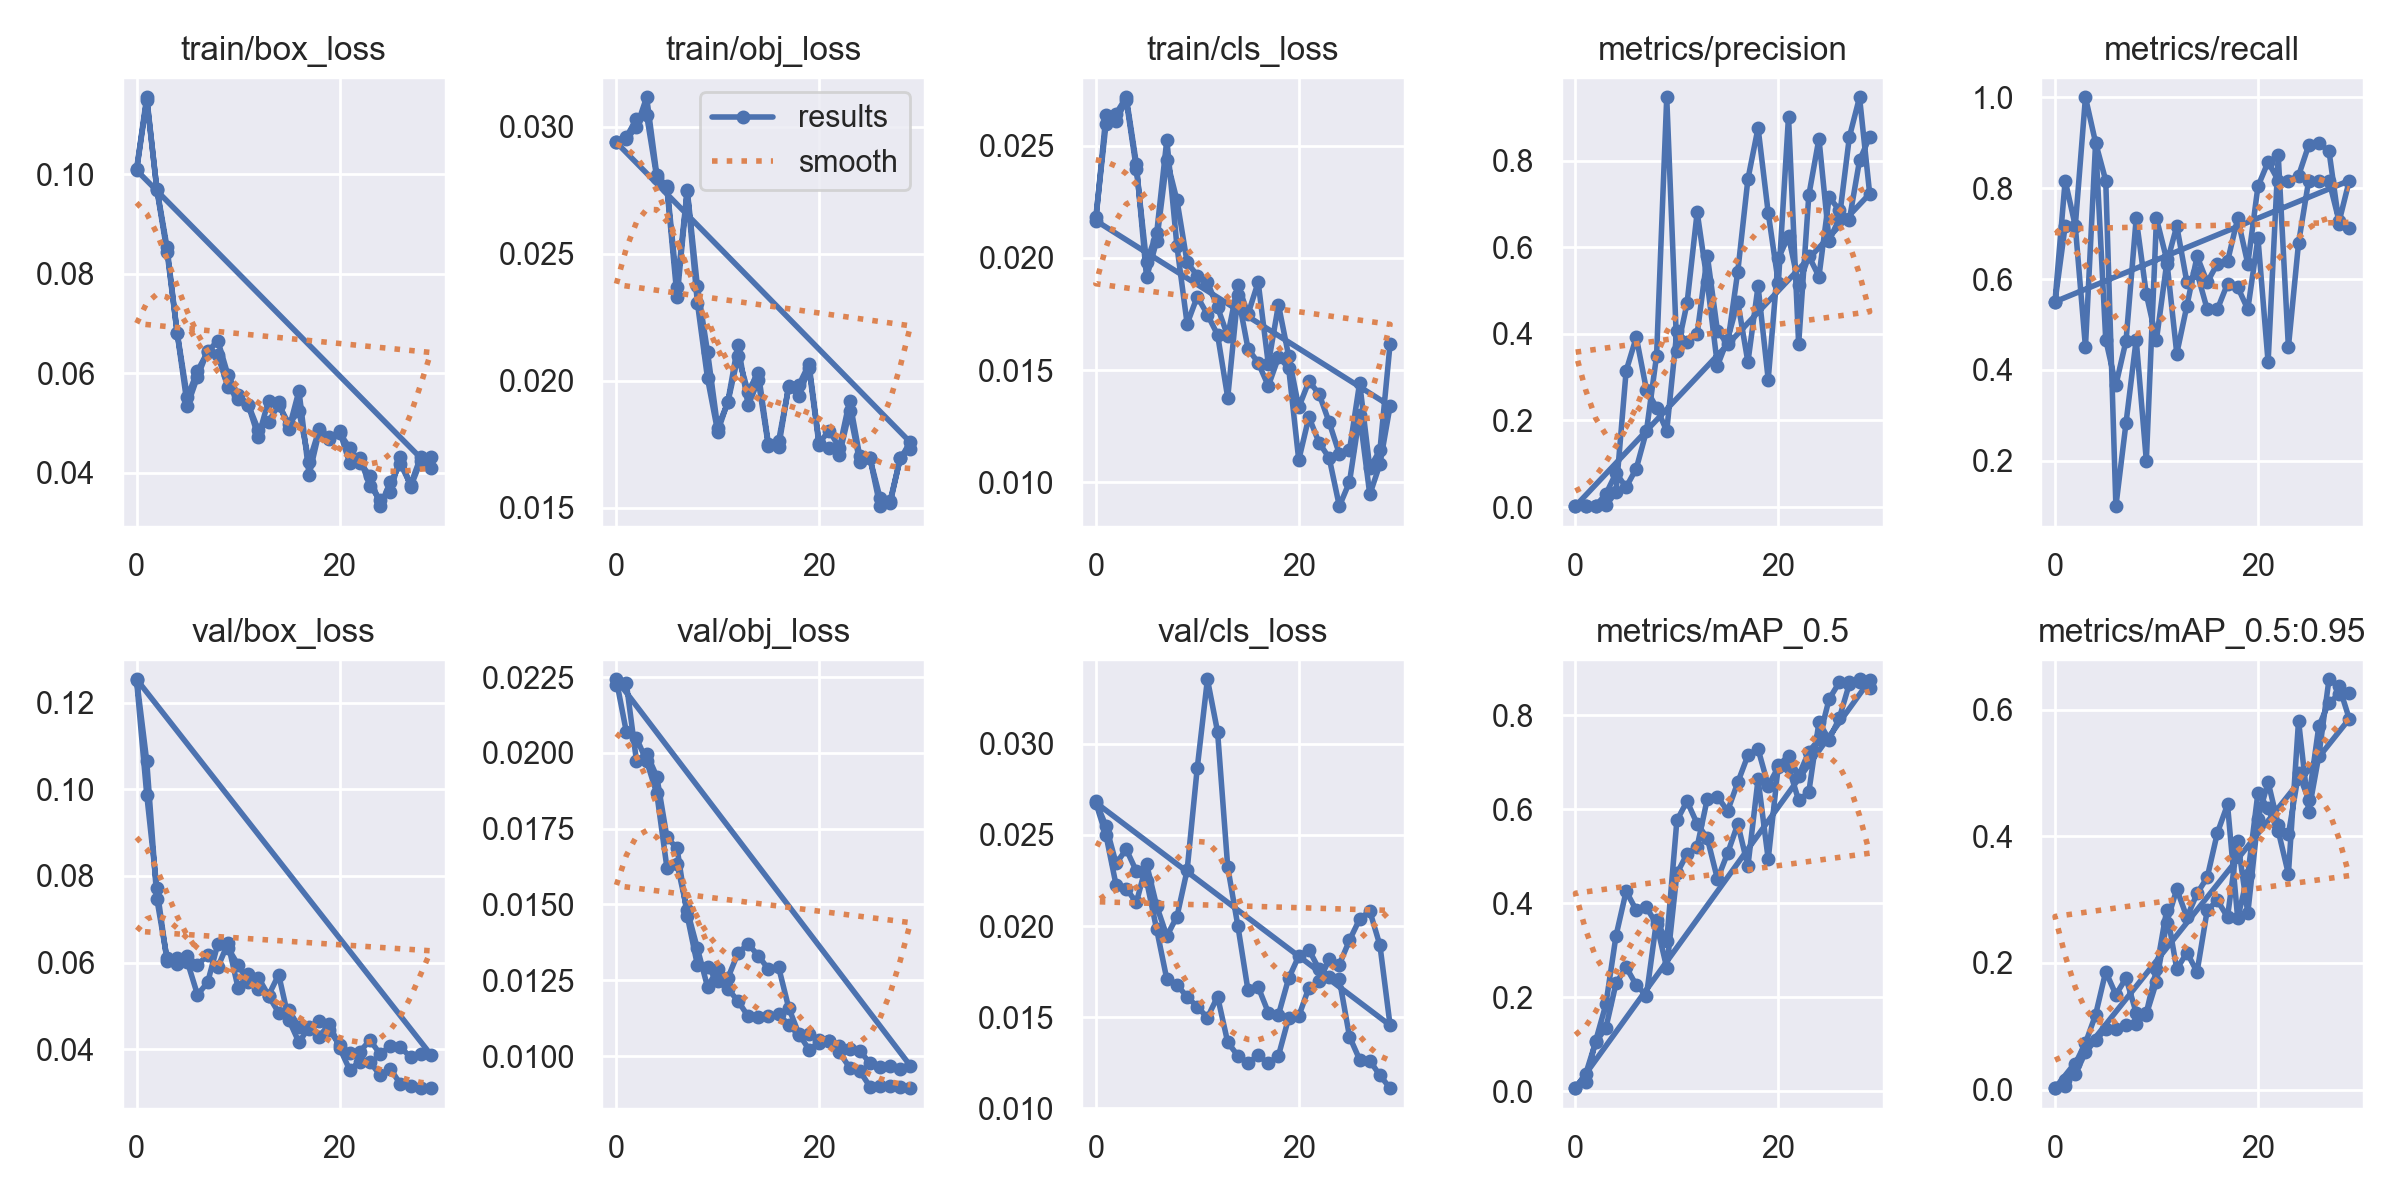

In [9]:

from IPython.display import Image, display

caminho = (
    '/content/drive/MyDrive/'
    'YOLO_Resultados/treino_30/results.png'
)

display(Image(filename=caminho))


*O treinamento do YOLOv5s adaptável com 30 épocas apresentou resultados positivos na identificação das duas classes personalizadas: controle PS5 e garrafa térmica.*

*Na etapa de validação, o modelo alcançou mAP@0.5 de `87,7%` e mAP@0.5:0.95 de `62,4%`, indicando que conseguiu aprender características relevantes dos objetos e localizar suas posições nas imagens.*

*O treinamento foi concluído em aproximadamente `6,92 minutos`, demonstrando um custo computacional relativamente baixo para a adaptação do modelo.*

*Os resultados indicam que 30 épocas foram suficientes para obter um desempenho inicial satisfatório. Entretanto, a diferença entre as métricas de mAP sugere que ainda existe espaço para melhorar a precisão das caixas delimitadoras, especialmente quando são utilizados critérios mais rigorosos de sobreposição.*

### Treinando YOLO adaptável com 60 épocas

*Nesta etapa, realizamos o segundo treinamento do YOLO adaptável, utilizando o mesmo modelo YOLOv5s e o mesmo dataset personalizado, porém aumentando a quantidade de épocas de 30 para 60.*

*O objetivo é avaliar como o aumento do tempo de treinamento influencia a capacidade do modelo de reconhecer e localizar os objetos, observando possíveis melhorias nas métricas de precisão, recall e mAP, além de identificar sinais de overfitting.*

*Para garantir uma comparação consistente, mantivemos os mesmos parâmetros do primeiro experimento, alterando apenas a quantidade de épocas. O treinamento será iniciado novamente a partir dos pesos pré-treinados originais, e não dos pesos obtidos no experimento de 30 épocas.*

*Também será registrado o tempo total de treinamento, permitindo analisar a relação entre o custo computacional e os resultados obtidos.*

In [10]:

import time

# Inicia a contagem do tempo total de treinamento.
inicio_60 = time.perf_counter()

# Executa o treinamento do YOLOv5s por 60 épocas,
# mantendo os parâmetros utilizados no experimento anterior.
!python /content/yolov5/train.py \
  --data /content/drive/MyDrive/dataset/dataset.yaml \
  --weights yolov5s.pt \
  --img 640 \
  --batch 8 \
  --epochs 60 \
  --device 0 \
  --project /content/drive/MyDrive/YOLO_Resultados \
  --name treino_60 \
  --exist-ok

# Calcula o tempo decorrido após a conclusão do treinamento.
tempo_60 = time.perf_counter() - inicio_60

# Apresenta o tempo total em segundos e minutos.
print(f"Tempo total: {tempo_60:.2f} segundos")
print(f"Tempo total: {tempo_60 / 60:.2f} minutos")


WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791895544.724446    6237 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/drive/MyDrive/dataset/dataset.yaml, hyp=yolov5/data/hyps/hyp.scratch-low.yaml, epochs=60, batch_size=8, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=yolov5/data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=0, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn

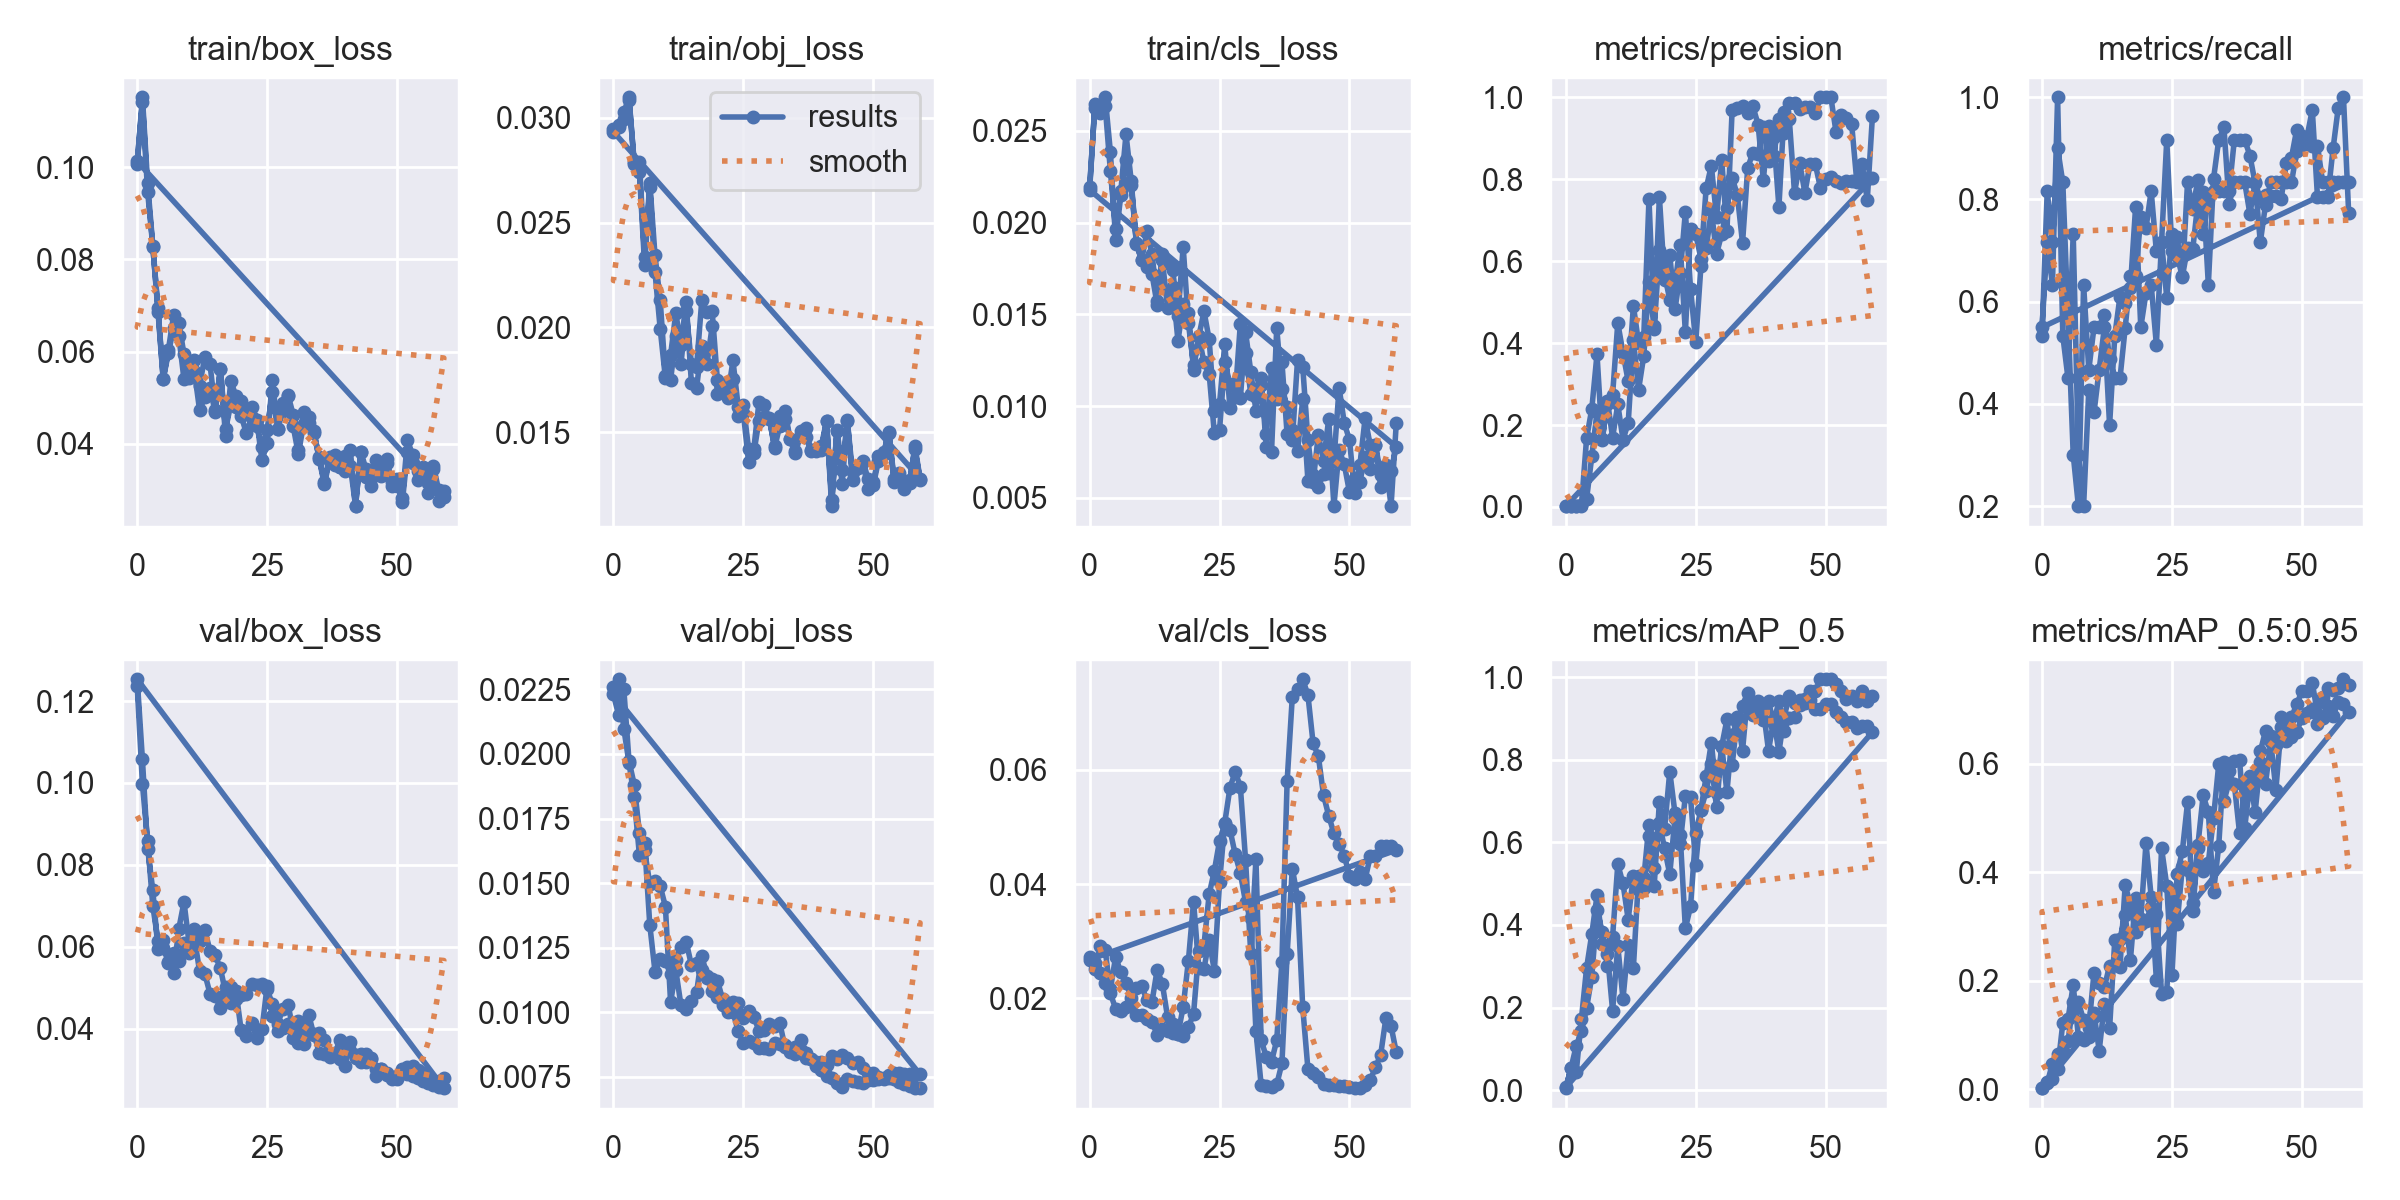

In [11]:

from IPython.display import Image, display

caminho = (
    '/content/drive/MyDrive/'
    'YOLO_Resultados/treino_60/results.png'
)

display(Image(filename=caminho))


*O treinamento do YOLOv5s adaptável com 60 épocas apresentou resultados positivos na identificação das duas classes personalizadas: controle PS5 e garrafa térmica.*

*Na etapa de validação, o modelo alcançou **mAP@0.5 de `94,3%`** e **mAP@0.5:0.95 de `75,6%`**, demonstrando uma melhora em relação ao treinamento com 30 épocas, que obteve `87,7%` e `62,4%`, respectivamente.*

*O modelo também apresentou **Recall de 100%** na validação, indicando que conseguiu identificar todos os objetos anotados nesse conjunto. Entretanto, a Precision de `75,1%` demonstra que ainda ocorreram detecções incorretas.*

*O treinamento foi concluído em aproximadamente `11,09 minutos`, exigindo maior tempo computacional em comparação com o modelo de 30 épocas.*

*Os resultados sugerem que o aumento do número de épocas contribuiu para melhorar a capacidade de detecção e a precisão das caixas delimitadoras.*

### Teste dos dois modelos

*Nesta etapa, avaliamos os dois modelos YOLO adaptáveis utilizando o conjunto de teste, composto por 10 imagens que não foram utilizadas durante o treinamento ou a validação.*

*O objetivo é verificar a capacidade de generalização dos modelos treinados por 30 e 60 épocas, analisando métricas como **precision, recall, mAP50 e mAP50-95**.*

*Para garantir uma comparação consistente, ambos os modelos serão avaliados com os mesmos parâmetros e imagens de teste, utilizando os melhores pesos salvos durante cada treinamento (`best.pt`). Os resultados permitirão identificar se o aumento da quantidade de épocas proporcionou melhorias no desempenho de detecção e localização dos objetos.*

In [12]:
#################################
#    Teste modelo 30 épocas     #
#################################

# Avalia o modelo treinado por 30 épocas utilizando as imagens de teste.
# Carrega os melhores pesos e calcula as métricas de detecção.
!python /content/yolov5/val.py \
  --weights /content/drive/MyDrive/YOLO_Resultados/treino_30/weights/best.pt \
  --data /content/drive/MyDrive/dataset/dataset.yaml \
  --task test \
  --img 640 \
  --batch 8 \
  --device 0 \
  --project /content/drive/MyDrive/YOLO_Resultados \
  --name teste_30 \
  --exist-ok


val: data=/content/drive/MyDrive/dataset/dataset.yaml, weights=['/content/drive/MyDrive/YOLO_Resultados/treino_30/weights/best.pt'], batch_size=8, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=test, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=/content/drive/MyDrive/YOLO_Resultados, name=teste_30, exist_ok=True, half=False, dnn=False
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning /content/drive/MyDrive/dataset/labels/test.cache... 10 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 2/2 3.5s/it 7.1s
                   all         10         10      0.912      0.881      0.888      0.511
          controle_ps5         10          5    

In [13]:
#################################
#    Teste modelo 60 épocas     #
#################################

# Avalia o modelo treinado por 60 épocas utilizando o mesmo conjunto de teste.
# Mantém os parâmetros de avaliação para permitir a comparação dos resultados.
!python /content/yolov5/val.py \
  --weights /content/drive/MyDrive/YOLO_Resultados/treino_60/weights/best.pt \
  --data /content/drive/MyDrive/dataset/dataset.yaml \
  --task test \
  --img 640 \
  --batch 8 \
  --device 0 \
  --project /content/drive/MyDrive/YOLO_Resultados \
  --name teste_60 \
  --exist-ok


val: data=/content/drive/MyDrive/dataset/dataset.yaml, weights=['/content/drive/MyDrive/YOLO_Resultados/treino_60/weights/best.pt'], batch_size=8, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=test, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=/content/drive/MyDrive/YOLO_Resultados, name=teste_60, exist_ok=True, half=False, dnn=False
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning /content/drive/MyDrive/dataset/labels/test.cache... 10 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 2/2 1.5it/s 1.4s
                   all         10         10       0.96        0.8      0.879      0.635
          controle_ps5         10          5    

*O modelo treinado com 30 épocas apresentou Precision de `91,2%`, Recall de `88,1%`, mAP@0.5 de `88,8%` e mAP@0.5:0.95 de `51,1%`. Esses resultados indicam um bom desempenho na identificação dos objetos, com maior capacidade de recuperação das detecções esperadas.*

*Já o modelo treinado com 60 épocas alcançou Precision de `96,0%`, Recall de `80,0%`, mAP@0.5 de `87,9%` e mAP@0.5:0.95 de `63,5%`. Apesar da pequena redução no Recall e no mAP@0.5, apresentou maior precisão nas detecções e melhor desempenho na localização dos objetos sob critérios mais rigorosos de sobreposição.*

*A comparação demonstra que o aumento de 30 para 60 épocas não melhorou todas as métricas, mas contribuiu para elevar o mAP@0.5:0.95, sugerindo maior qualidade das caixas delimitadoras.*

*Dessa forma, o modelo de 60 épocas apresentou o melhor resultado quando considerada a precisão da localização dos objetos, enquanto o modelo de 30 épocas obteve maior Recall e um mAP@0.5 ligeiramente superior.*

### Gerando imagens de teste

*Nesta etapa, utilizamos os modelos YOLO adaptáveis treinados por 30 e 60 épocas para gerar imagens com as detecções realizadas sobre o conjunto de teste.*

*O objetivo é **analisar visualmente a capacidade dos modelos de identificar e localizar o controle PS5 e a garrafa térmica**, observando as caixas delimitadoras (*bounding boxes*), as classes previstas e os níveis de confiança das detecções.*

*As imagens serão processadas utilizando os melhores pesos de cada treinamento e um limiar mínimo de confiança de 25%. Os resultados serão armazenados em diretórios separados, permitindo comparar visualmente o comportamento dos dois modelos e identificar possíveis diferenças, como objetos não detectados, classificações incorretas ou variações na localização das caixas.*

In [14]:
#################################
#       Imagem 30 épocas        #
#################################

# Executa a detecção nas imagens de teste com o modelo treinado por 30 épocas.
# Gera imagens com caixas delimitadoras, classes e níveis de confiança.
!python /content/yolov5/detect.py \
  --weights /content/drive/MyDrive/YOLO_Resultados/treino_30/weights/best.pt \
  --source /content/drive/MyDrive/dataset/images/test \
  --img 640 \
  --conf 0.25 \
  --device 0 \
  --project /content/drive/MyDrive/YOLO_Resultados \
  --name deteccoes_30 \
  --exist-ok


detect: weights=['/content/drive/MyDrive/YOLO_Resultados/treino_30/weights/best.pt'], source=/content/drive/MyDrive/dataset/images/test, data=yolov5/data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=0, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=/content/drive/MyDrive/YOLO_Resultados, name=deteccoes_30, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/10 /content/drive/MyDrive/dataset/images/test/controle_014.jpeg: 640x480 1 controle_ps5, 36.1ms
image 2/10 /content/drive/MyDrive/dataset/images/test/controle_025.jpeg: 640x480 1 controle_ps5, 13.2ms
image 3/10 /content/d

In [15]:
#################################
#       Imagem 60 épocas        #
#################################

# Executa a detecção nas mesmas imagens utilizando o modelo de 60 épocas.
# Mantém os parâmetros para permitir a comparação visual entre os modelos.
!python /content/yolov5/detect.py \
  --weights /content/drive/MyDrive/YOLO_Resultados/treino_60/weights/best.pt \
  --source /content/drive/MyDrive/dataset/images/test \
  --img 640 \
  --conf 0.25 \
  --device 0 \
  --project /content/drive/MyDrive/YOLO_Resultados \
  --name deteccoes_60 \
  --exist-ok


detect: weights=['/content/drive/MyDrive/YOLO_Resultados/treino_60/weights/best.pt'], source=/content/drive/MyDrive/dataset/images/test, data=yolov5/data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=0, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=/content/drive/MyDrive/YOLO_Resultados, name=deteccoes_60, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/10 /content/drive/MyDrive/dataset/images/test/controle_014.jpeg: 640x480 1 controle_ps5, 1 garrafa_termica, 35.7ms
image 2/10 /content/drive/MyDrive/dataset/images/test/controle_025.jpeg: 640x480 1 controle_ps5, 13.2ms
im

### Analisando tempo de treinamento e inferência

*Nesta etapa, analisamos o desempenho computacional dos modelos YOLO adaptáveis treinados por 30 e 60 épocas, considerando o tempo necessário para o treinamento e para a execução das detecções.*

*Inicialmente, recuperamos os tempos de treinamento registrados nos experimentos anteriores. Em seguida, carregamos os melhores pesos de cada modelo e medimos o tempo necessário para processar as 10 imagens do conjunto de teste.*

*Para tornar a medição mais consistente, realizamos um aquecimento inicial da GPU e utilizamos a sincronização CUDA antes e depois da execução. Os resultados são apresentados em tempo total e tempo médio por imagem.*

*O objetivo é **avaliar o impacto do aumento da quantidade de épocas sobre o custo computacional**, permitindo comparar os tempos de treinamento e inferência dos dois modelos e relacioná-los às métricas de detecção obtidas anteriormente.*

In [16]:

# Recupera os tempos registrados durante os treinamentos de 30 e 60 épocas.
for nome in ['tempo_30', 'tempo_60']:

    # Verifica se a variável ainda está disponível na sessão do Colab.
    if nome in globals():
        segundos = globals()[nome]

        # Converte o tempo de segundos para minutos.
        print(f'{nome}: {segundos / 60:.2f} minutos')
    else:
        print(f'{nome}: tempo não disponível na sessão')


tempo_30: 6.92 minutos
tempo_60: 11.09 minutos


In [17]:

import time
import torch
from pathlib import Path

# Define o diretório onde estão armazenados os modelos treinados.
pasta_pesos = Path(
    '/content/drive/MyDrive/YOLO_Resultados'
)

# Identifica os melhores pesos de cada experimento.
modelos = {
    '30 épocas': pasta_pesos / 'treino_30/weights/best.pt',
    '60 épocas': pasta_pesos / 'treino_60/weights/best.pt'
}

# Define o diretório das imagens utilizadas na avaliação.
pasta_teste = Path(
    '/content/drive/MyDrive/dataset/images/test'
)

# Seleciona as imagens de teste com extensões válidas.
imagens = sorted([
    str(p) for p in pasta_teste.iterdir()
    if p.suffix.lower() in ('.jpg', '.jpeg', '.png')
])

# Executa a medição de inferência separadamente para cada modelo.
for nome, pesos in modelos.items():

    # Carrega o modelo YOLOv5 com os pesos do respectivo treinamento.
    modelo = torch.hub.load(
        '/content/yolov5',
        'custom',
        path=str(pesos),
        source='local'
    )

    # Transfere o modelo para a GPU e configura o modo de avaliação.
    modelo.to('cuda')
    modelo.eval()

    # Realiza um aquecimento inicial para reduzir o impacto
    # das primeiras execuções na medição de desempenho.
    for imagem in imagens[:3]:
        modelo(imagem, size=640)

    # Aguarda a conclusão das operações pendentes na GPU.
    torch.cuda.synchronize()

    # Inicia a contagem do tempo de inferência.
    inicio = time.perf_counter()

    # Processa individualmente todas as imagens do conjunto de teste.
    for imagem in imagens:
        modelo(imagem, size=640)

    # Garante que todas as operações da GPU foram concluídas.
    torch.cuda.synchronize()

    # Calcula o tempo total de processamento das imagens.
    tempo_total = time.perf_counter() - inicio

    # Apresenta o tempo total e a média por imagem.
    print(f'\n{nome}')
    print(f'Tempo total: {tempo_total:.3f} s')
    print(f'Tempo médio: {tempo_total / len(imagens) * 1000:.2f} ms/imagem')


YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 

30 épocas
Tempo total: 0.476 s
Tempo médio: 47.56 ms/imagem
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 

60 épocas
Tempo total: 0.508 s
Tempo médio: 50.76 ms/imagem


*O modelo treinado por 60 épocas apresentou um tempo de treinamento aproximadamente 60% maior em relação ao modelo de 30 épocas, o que é esperado devido ao aumento da quantidade de ciclos de treinamento.*

*Em relação à inferência, os tempos foram próximos, com uma diferença de aproximadamente 3,20 ms por imagem. Isso ocorre porque ambos utilizam a mesma arquitetura YOLOv5s, independentemente da quantidade de épocas utilizadas no treinamento.*

*Dessa forma, o aumento das épocas impactou principalmente o tempo de treinamento, sem provocar uma diferença expressiva no tempo de inferência observado.*

### Conclusão Entrega 1

*YOLO adaptável (30 e 60 épocas)*

*O desenvolvimento do sistema de visão computacional utilizando YOLOv5s permitiu avaliar a capacidade de detecção de dois objetos distintos: um controle de PlayStation 5 e uma garrafa térmica personalizada.*

*O dataset foi composto por 94 imagens, distribuídas entre treinamento (74), validação (10) e teste (10). As imagens foram rotuladas utilizando o Make Sense AI, e os treinamentos foram executados no Google Colab com GPU NVIDIA Tesla T4.*

*Foram realizados dois experimentos, com 30 e 60 épocas, utilizando a mesma arquitetura YOLOv5s e os mesmos conjuntos de imagens.*

**Resultados do modelo de 30 épocas**

*O primeiro modelo apresentou precision de `91,2%`, recall de `88,1%`, mAP@0.5 de `88,8%` e mAP@0.5:0.95 de `51,1%` no conjunto de teste.*

*O treinamento foi concluído em `6,92 minutos`, com tempo médio de inferência de `47,56 milissegundos` por imagem.*

**Resultados do modelo de 60 épocas**

*O segundo modelo apresentou precision de `96,0%`, recall de `80,0%`, mAP@0.5 de `87,9%` e mAP@0.5:0.95 de `63,5%` no conjunto de teste.*

*O treinamento foi concluído em `11,09 minutos`, com tempo médio de inferência de `50,76 milissegundos` por imagem.*

**Análise comparativa**

*O aumento de 30 para 60 épocas proporcionou uma melhoria de `4,8` pontos percentuais na precision e de `12,4` pontos percentuais no mAP@0.5:0.95, indicando maior precisão das detecções e melhor qualidade das caixas delimitadoras.*

*Entretanto, o recall diminuiu de `88,1%` para `80,0%`, enquanto o mAP@0.5 apresentou uma pequena redução de `88,8%` para `87,9%`. Esses resultados demonstram que aumentar a quantidade de épocas não melhora necessariamente todas as métricas de desempenho.*

*O tempo de treinamento aumentou aproximadamente `60,3%`, enquanto o tempo médio de inferência apresentou uma diferença de `3,20 milissegundos` por imagem. Como ambos os modelos utilizam a mesma arquitetura, essa diferença de inferência não permite concluir que o modelo de 60 épocas seja estruturalmente mais lento.*

*Na análise individual das classes, o modelo de 60 épocas apresentou melhor mAP@0.5:0.95 tanto para o controle de PlayStation 5 quanto para a garrafa térmica.*

*Na avaliação visual, ambos os modelos deixaram de identificar uma garrafa térmica entre as imagens processadas, considerando o limiar de confiança utilizado na inferência.*

*Os gráficos também evidenciaram oscilações na perda de classificação durante a validação, especialmente no treinamento de 60 épocas, sugerindo possível dificuldade de generalização nessa componente.*

**Conclusão final**

*Os dois modelos demonstraram capacidade de reconhecer os objetos propostos, mesmo em imagens contendo elementos adicionais no cenário.*

*O modelo de 60 épocas apresentou o melhor resultado em precision e mAP@0.5:0.95, sendo a alternativa mais interessante quando a prioridade é a qualidade da localização dos objetos.*

*Por outro lado, o modelo de 30 épocas apresentou maior recall, desempenho ligeiramente superior no mAP@0.5 e menor custo computacional, representando uma alternativa competitiva quando o tempo de treinamento e a recuperação dos objetos são fatores prioritários.*

*Dessa forma, os experimentos demonstraram que a quantidade de épocas influencia o desempenho do YOLOv5s, mas que o aumento do treinamento não garante melhorias uniformes em todas as métricas.*

*Por fim, considerando o tamanho reduzido do conjunto de teste, os resultados devem ser interpretados como evidências experimentais preliminares, não sendo possível garantir o mesmo desempenho em cenários mais amplos sem avaliações adicionais.*

### ***- Entrega 2 parte 1 - Utilizando Yolo Padrão ----------------------------------------***

### Executando detecção com YOLO padrão

In [18]:

# Executa a detecção utilizando o YOLOv5s com pesos originais do COCO,
# sem realizar treinamento adicional com o dataset personalizado.
!python /content/yolov5/detect.py \
  --weights yolov5s.pt \
  --source /content/drive/MyDrive/dataset/images/test \
  --img 640 \
  --conf 0.25 \
  --device 0 \
  --project /content/drive/MyDrive/YOLO_Padrao_Resultados \
  --name yolo_padrao_deteccoes \
  --save-txt \
  --save-conf


detect: weights=['yolov5s.pt'], source=/content/drive/MyDrive/dataset/images/test, data=yolov5/data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=0, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=/content/drive/MyDrive/YOLO_Padrao_Resultados, name=yolo_padrao_deteccoes, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
image 1/10 /content/drive/MyDrive/dataset/images/test/controle_014.jpeg: 640x480 1 cell phone, 1 refrigerator, 34.4ms
image 2/10 /content/drive/MyDrive/dataset/images/test/controle_025.jpeg: 640x480 (no detections), 10.3ms
image 3/10 /content/drive/MyDrive/dataset/

### Visualizando imagens processadas

*Nesta etapa, visualizamos as imagens processadas pelo YOLO padrão para analisar os objetos identificados pelo modelo, suas respectivas classes e as caixas delimitadoras (*bounding boxes*).*

*O objetivo é verificar visualmente os acertos, as classificações incorretas e os objetos que não foram detectados, permitindo compreender as limitações de um modelo pré-treinado que não foi adaptado às classes específicas do projeto.*

*Essa análise complementa o experimento anterior e fornece evidências para a comparação entre o YOLO padrão e os modelos personalizados.*

controle_014.jpeg


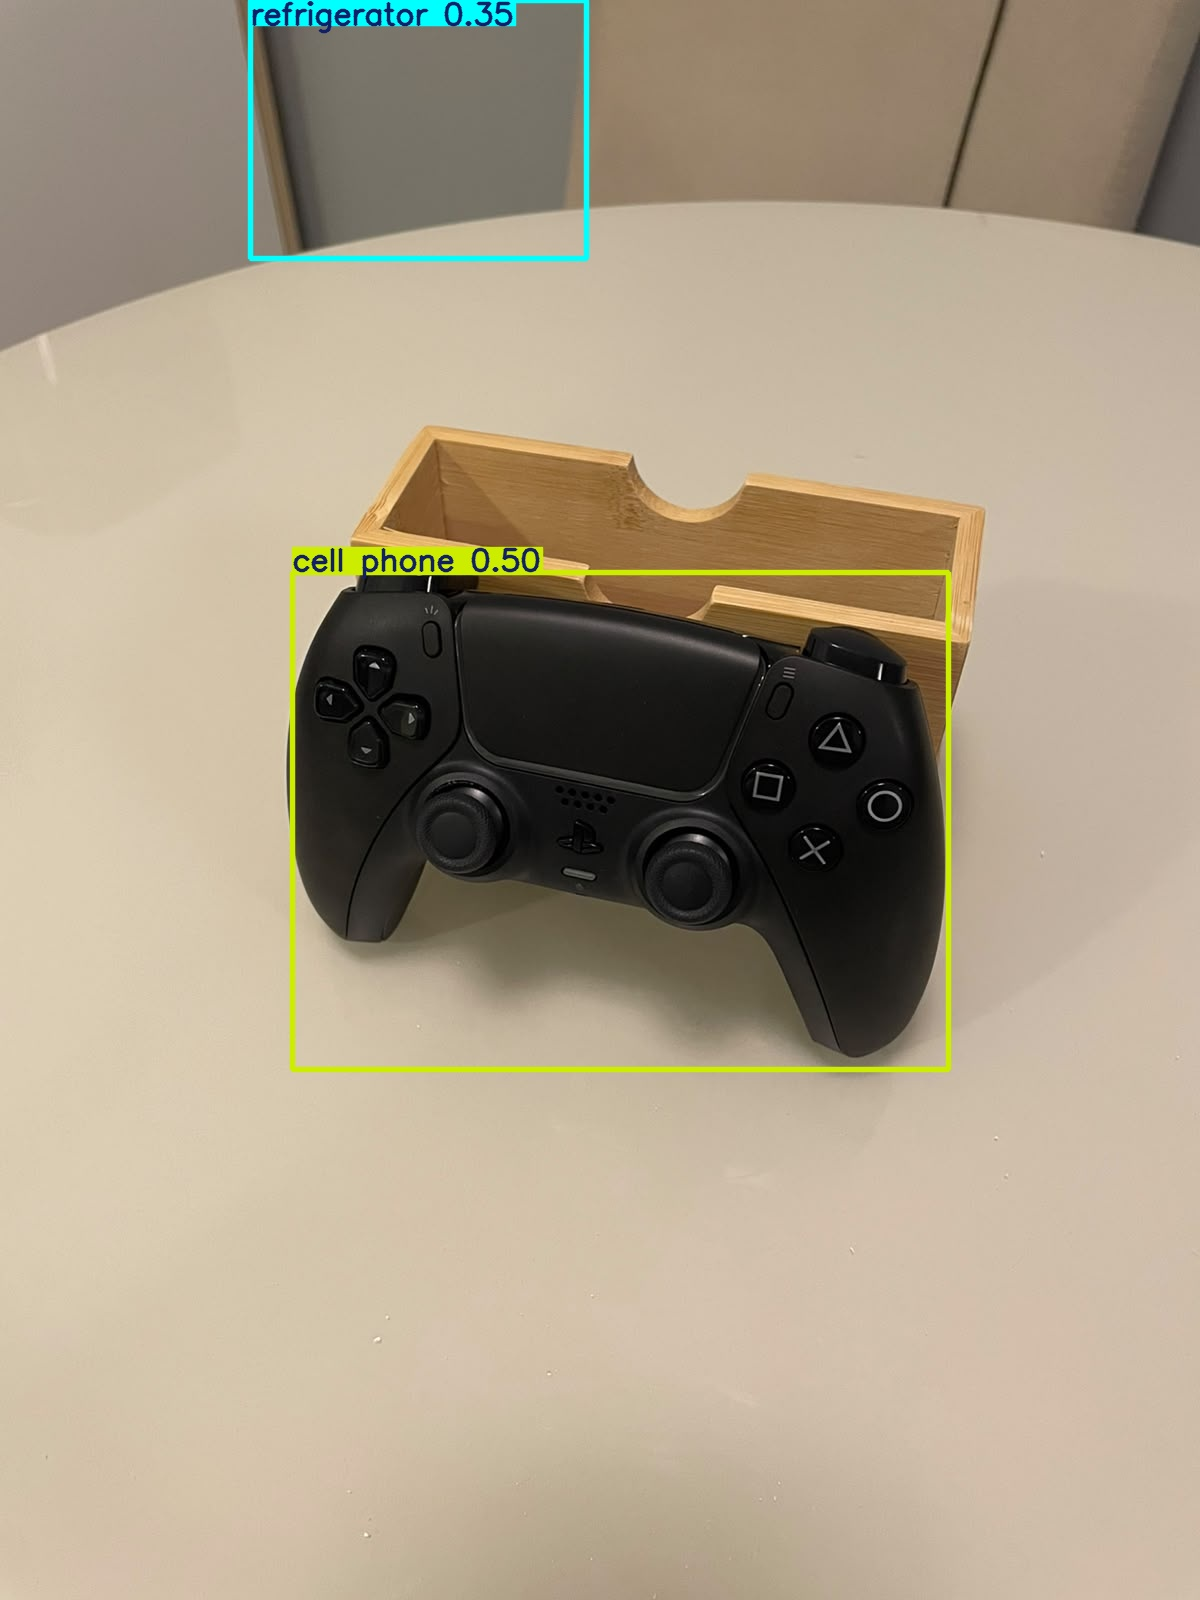

controle_025.jpeg


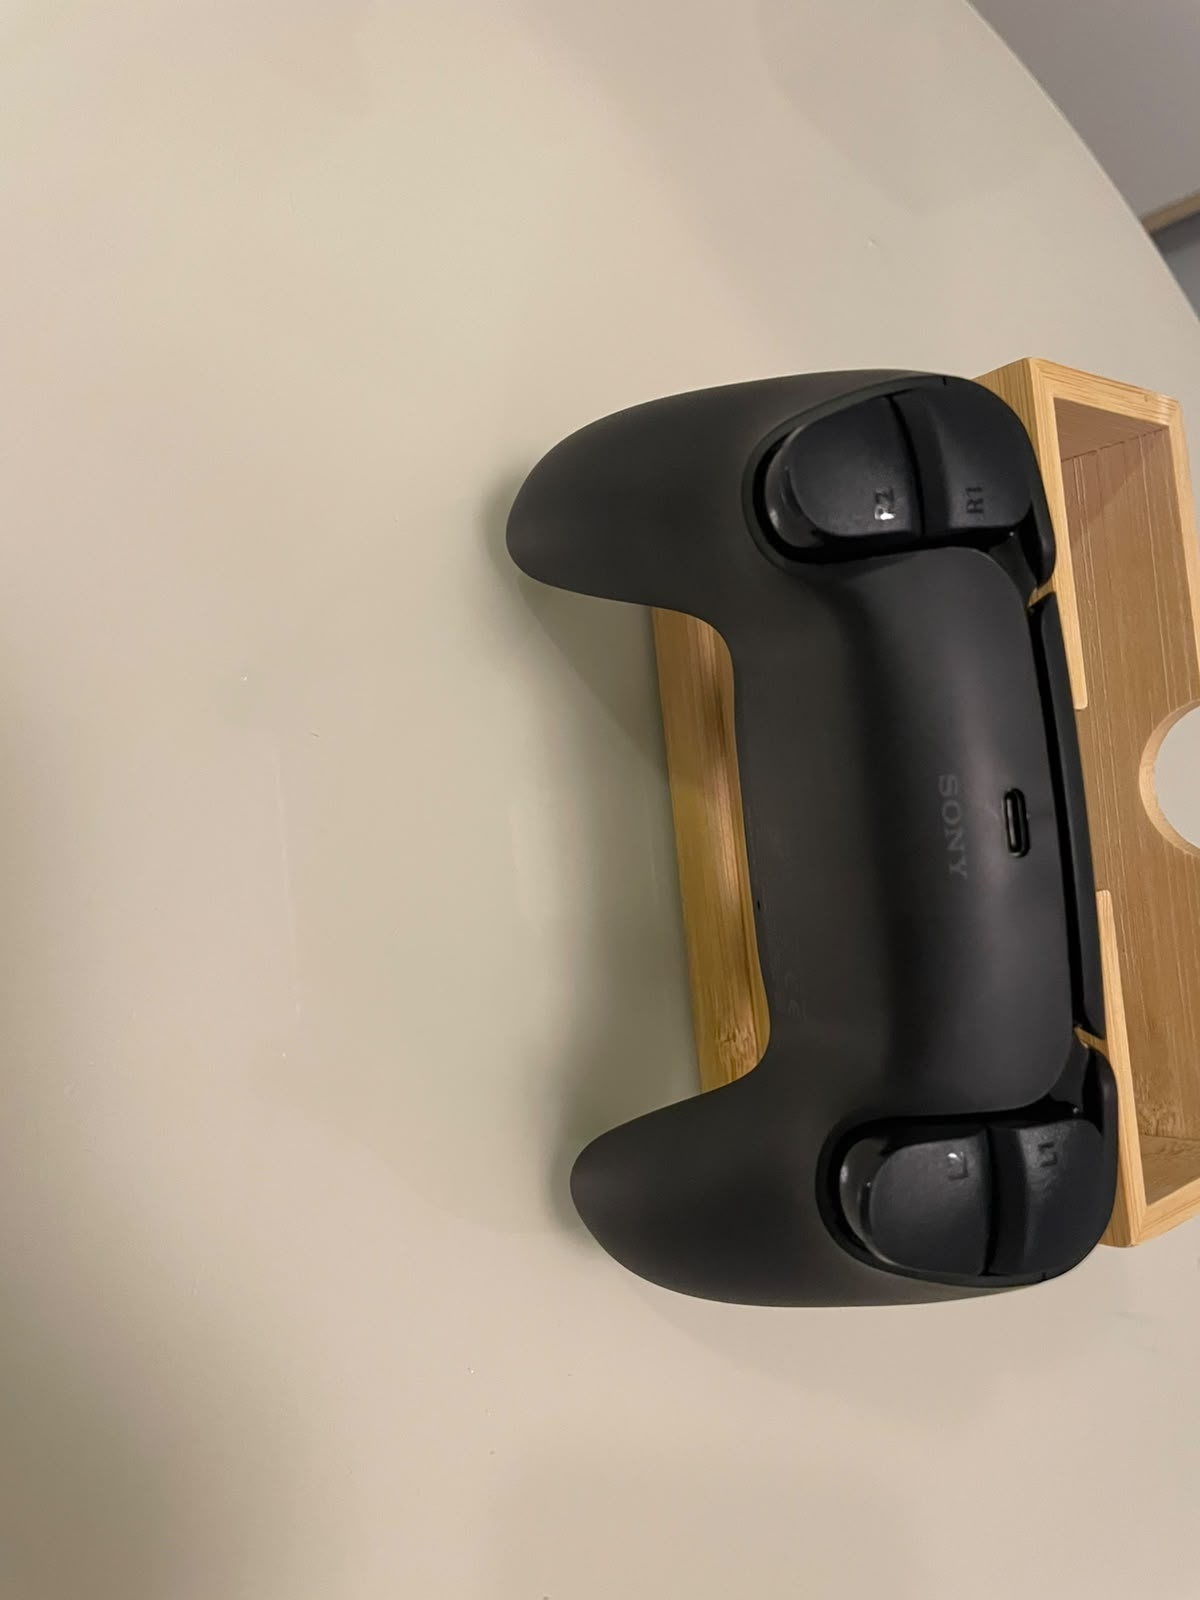

controle_029.jpeg


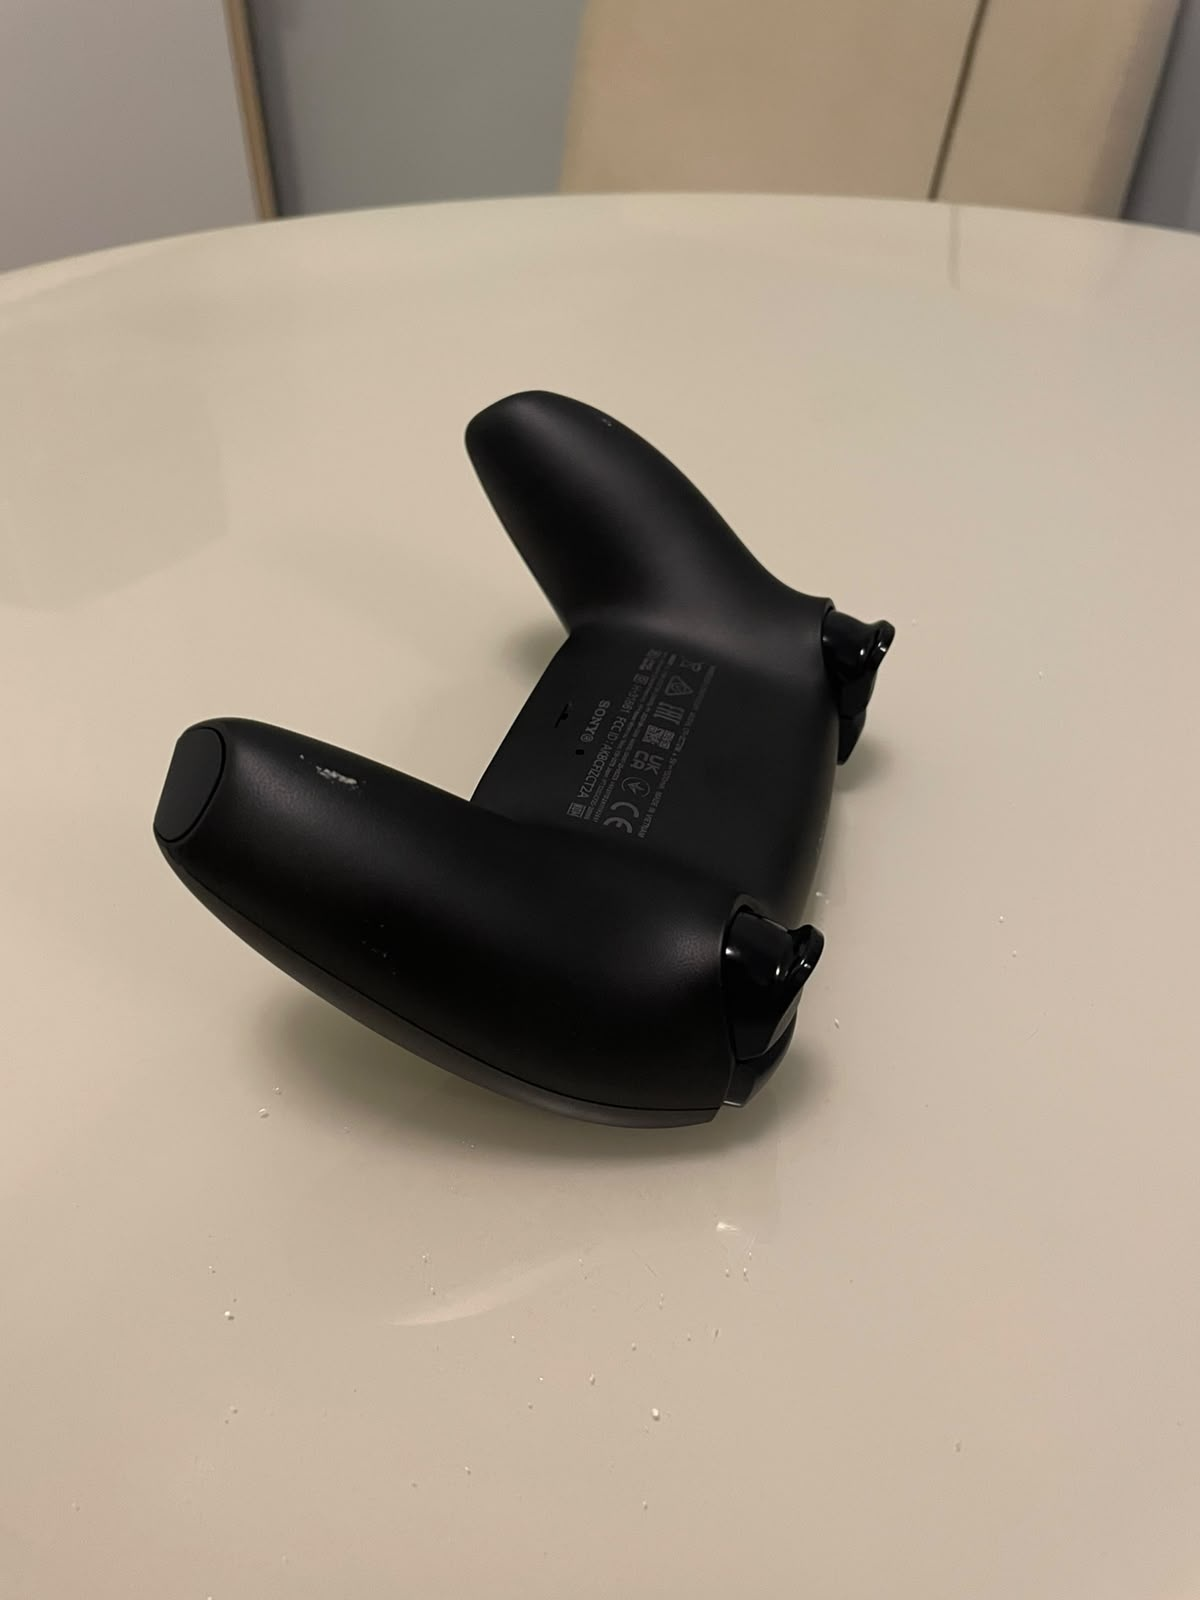

controle_033.jpeg


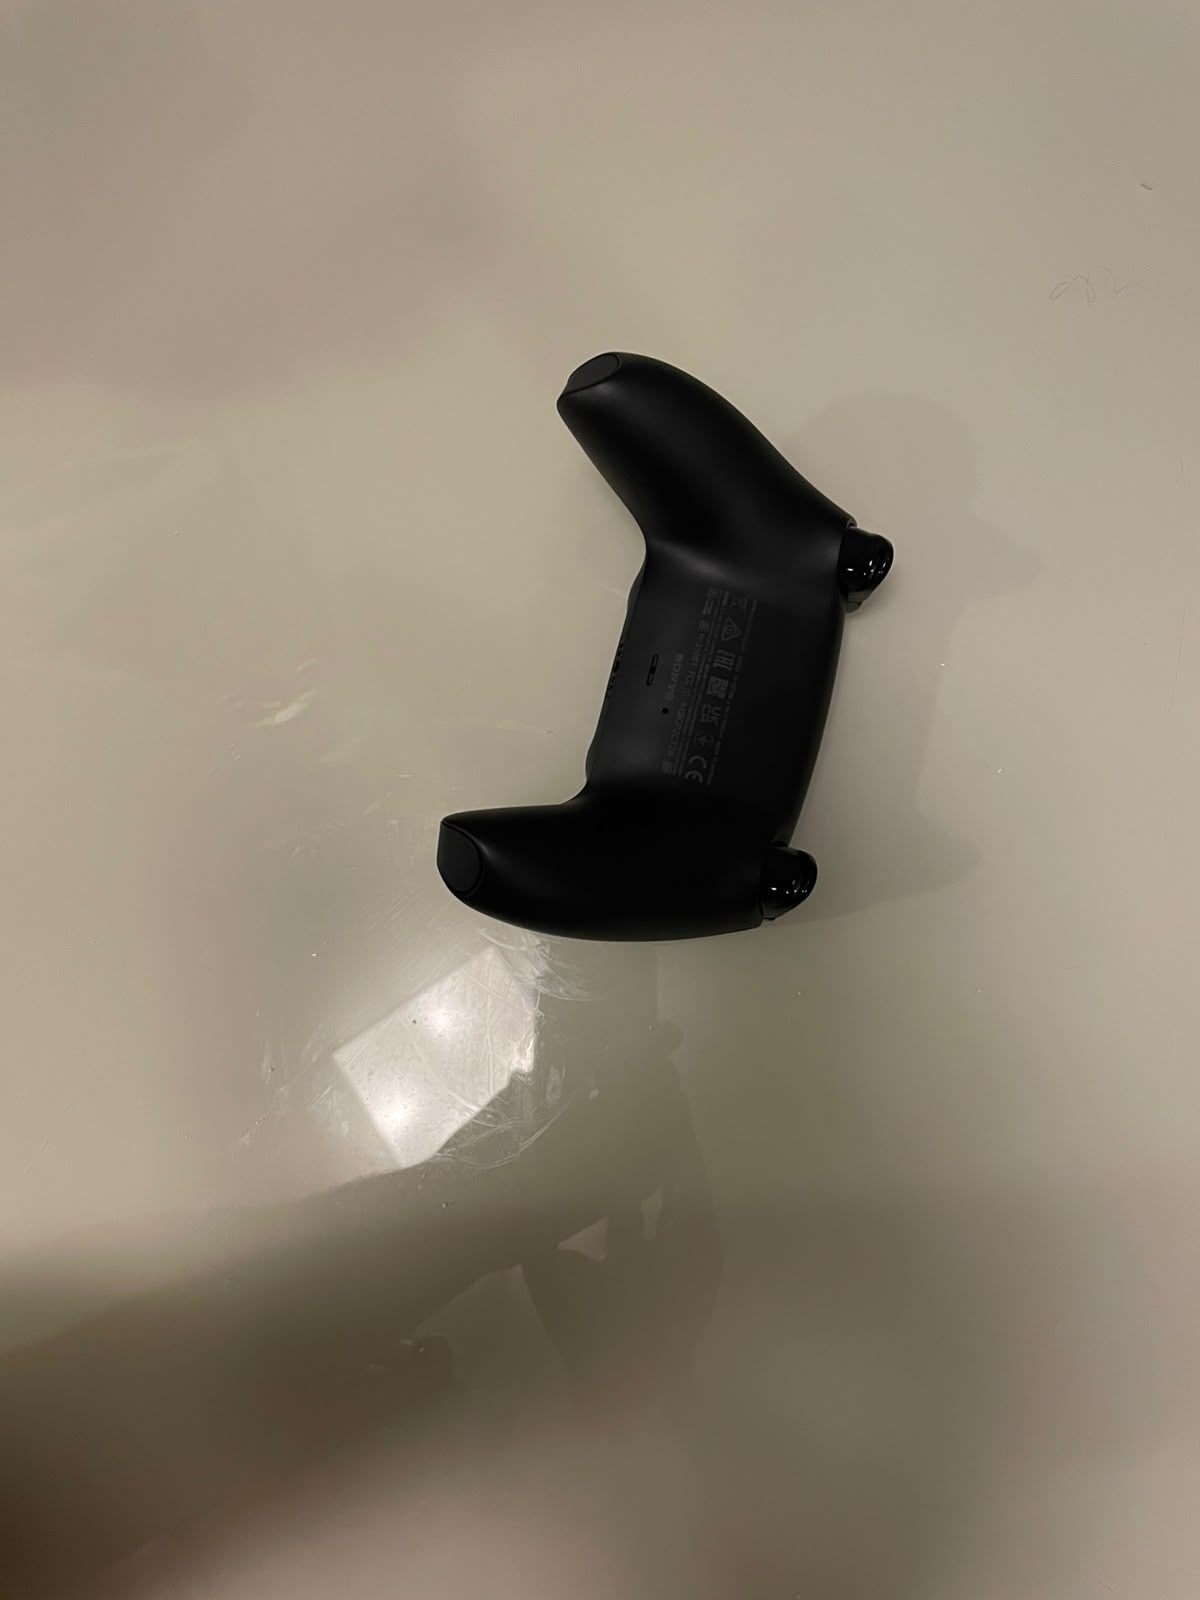

controle_041.jpeg


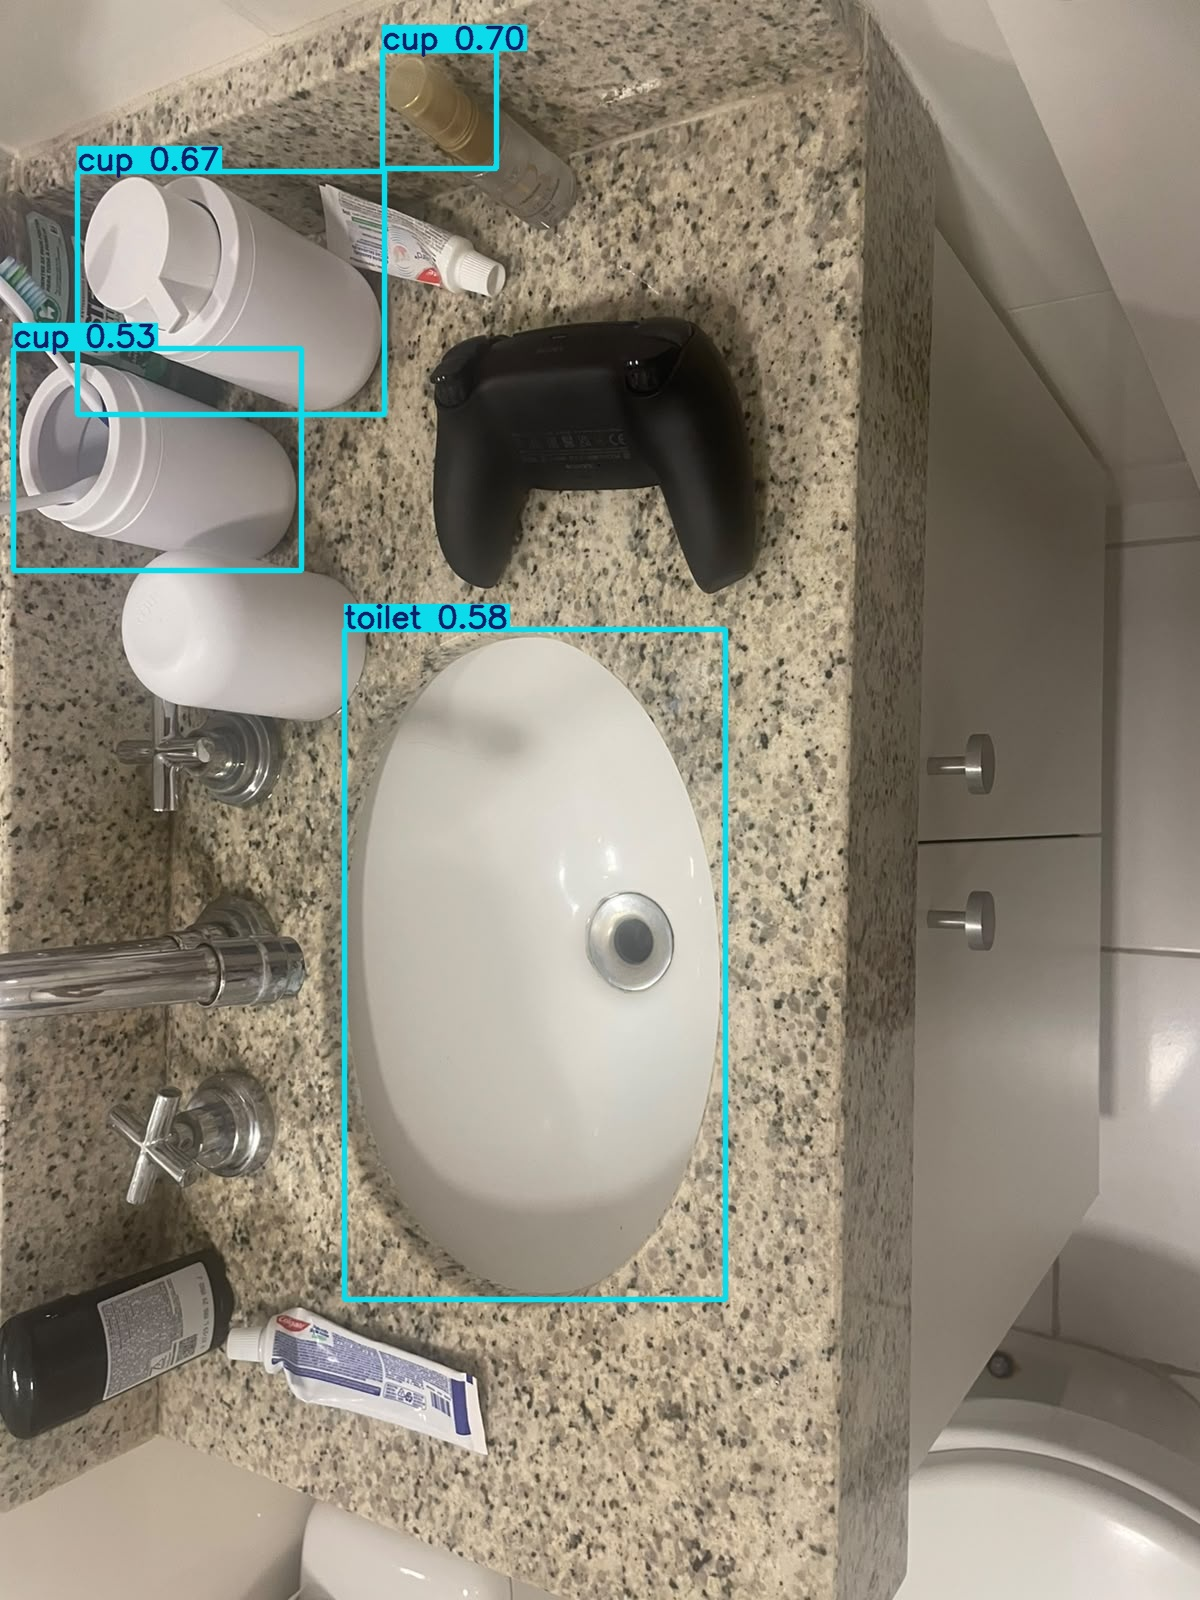

garrafa_004.jpeg


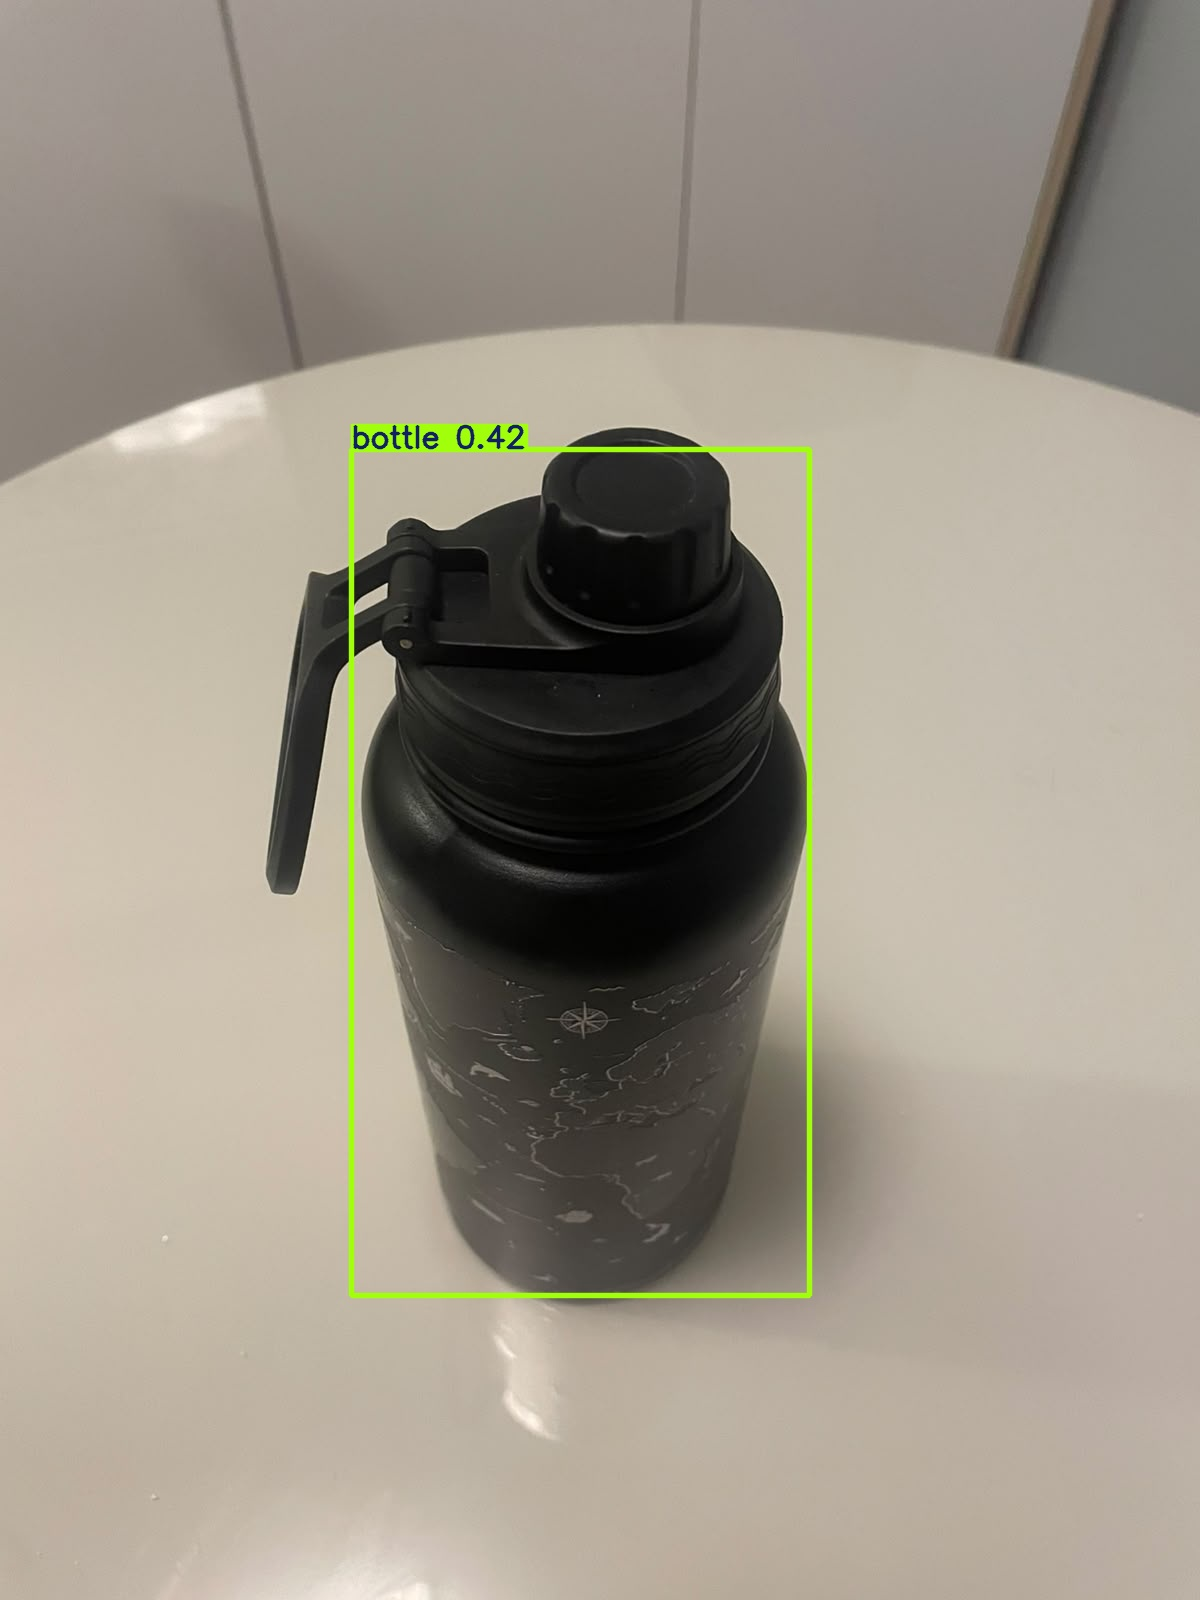

garrafa_014.jpeg


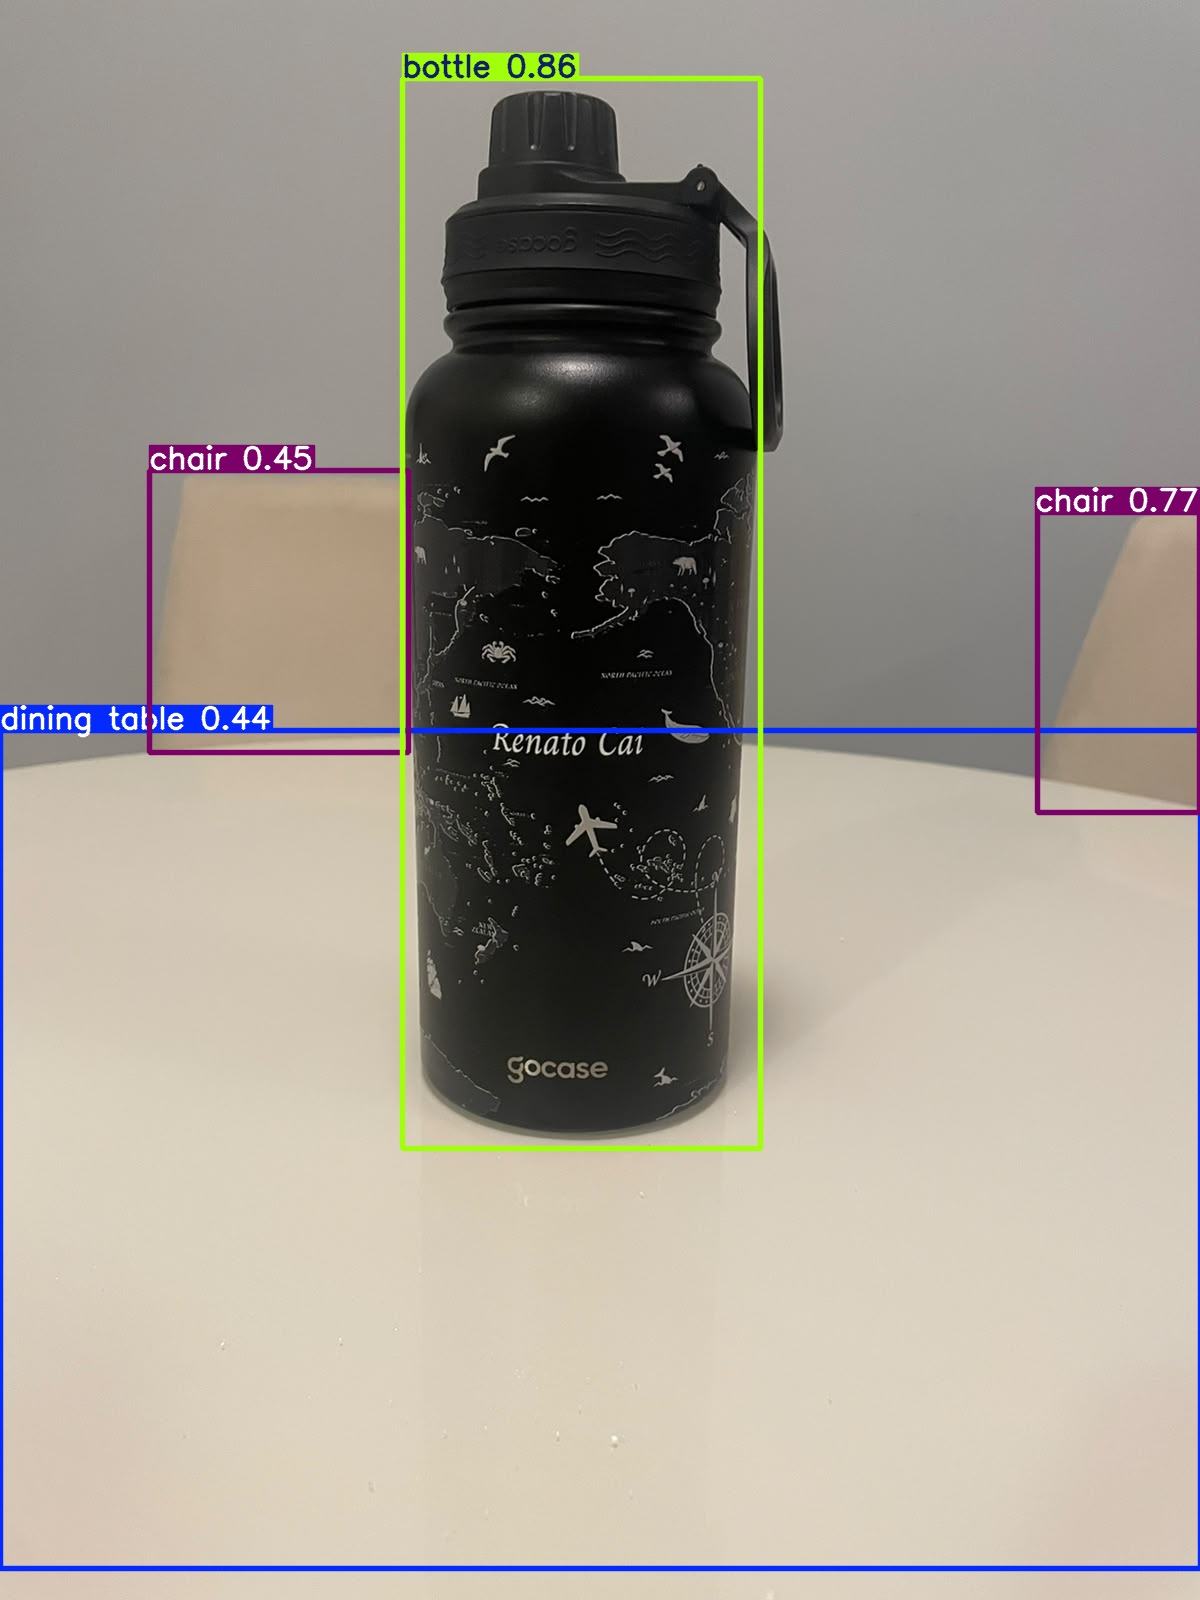

garrafa_021.jpeg


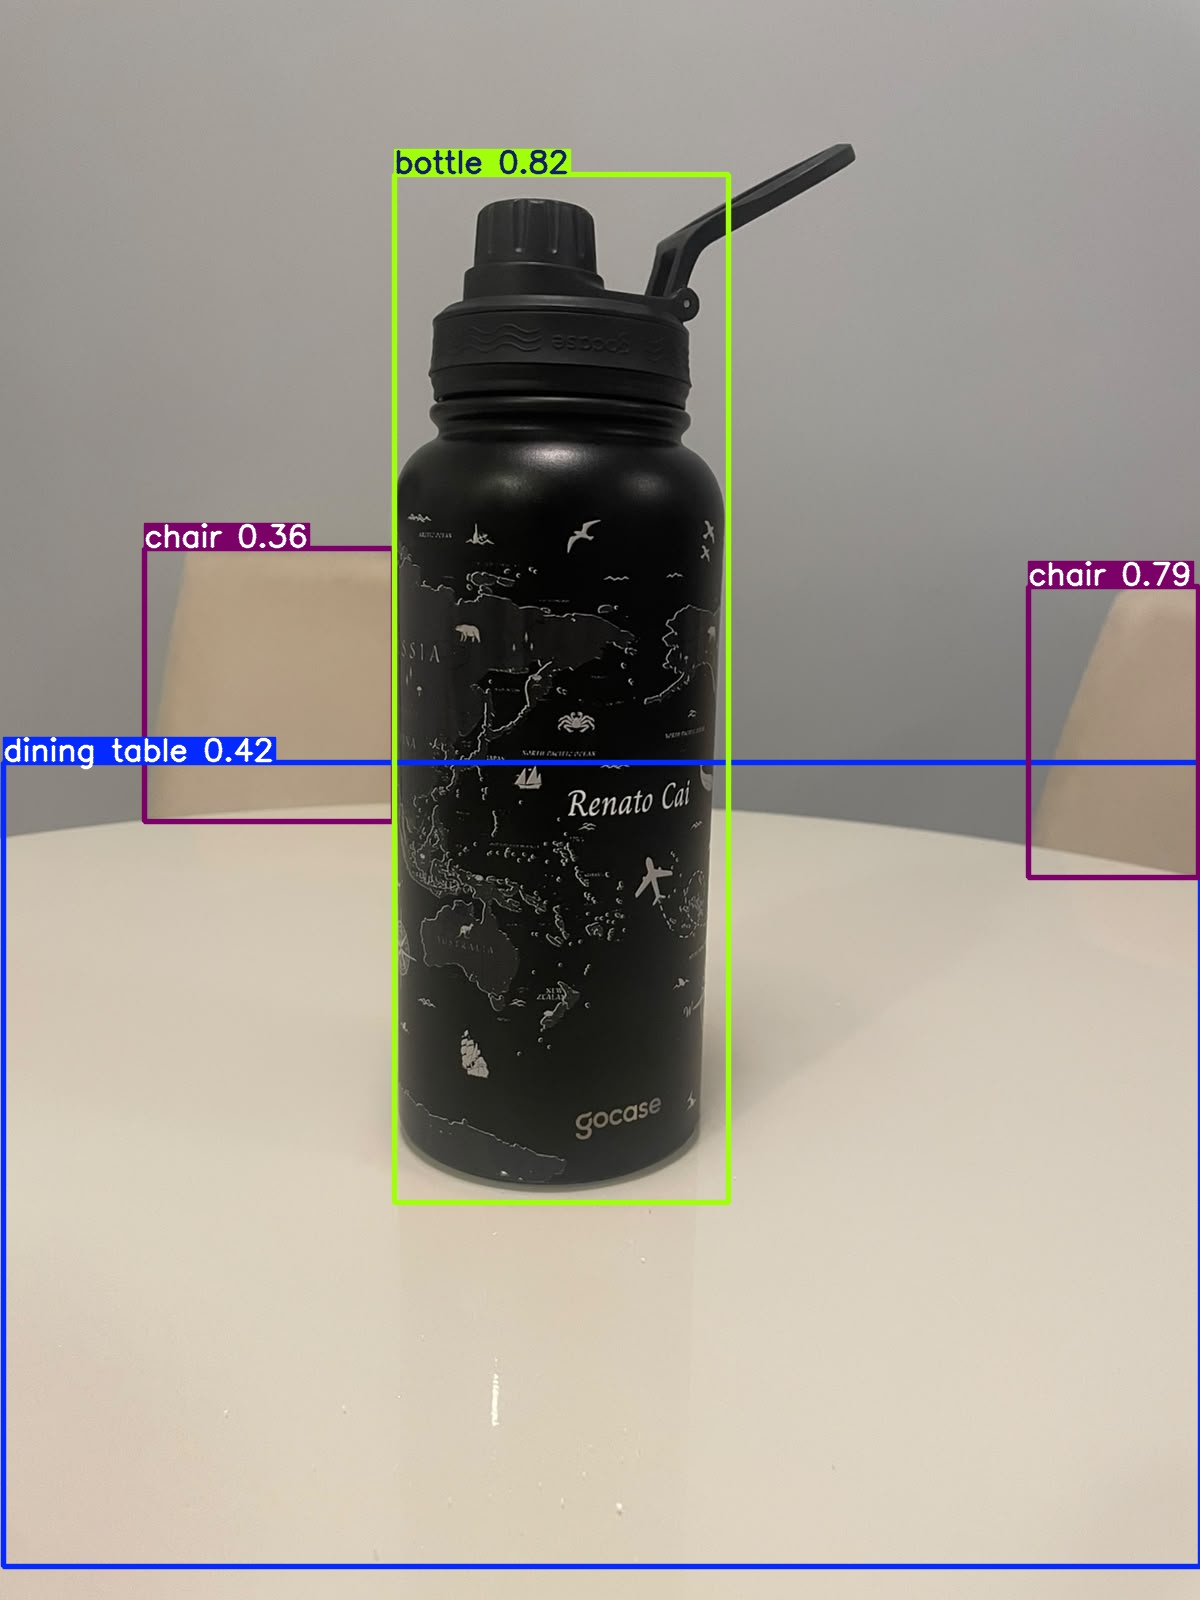

garrafa_027.jpeg


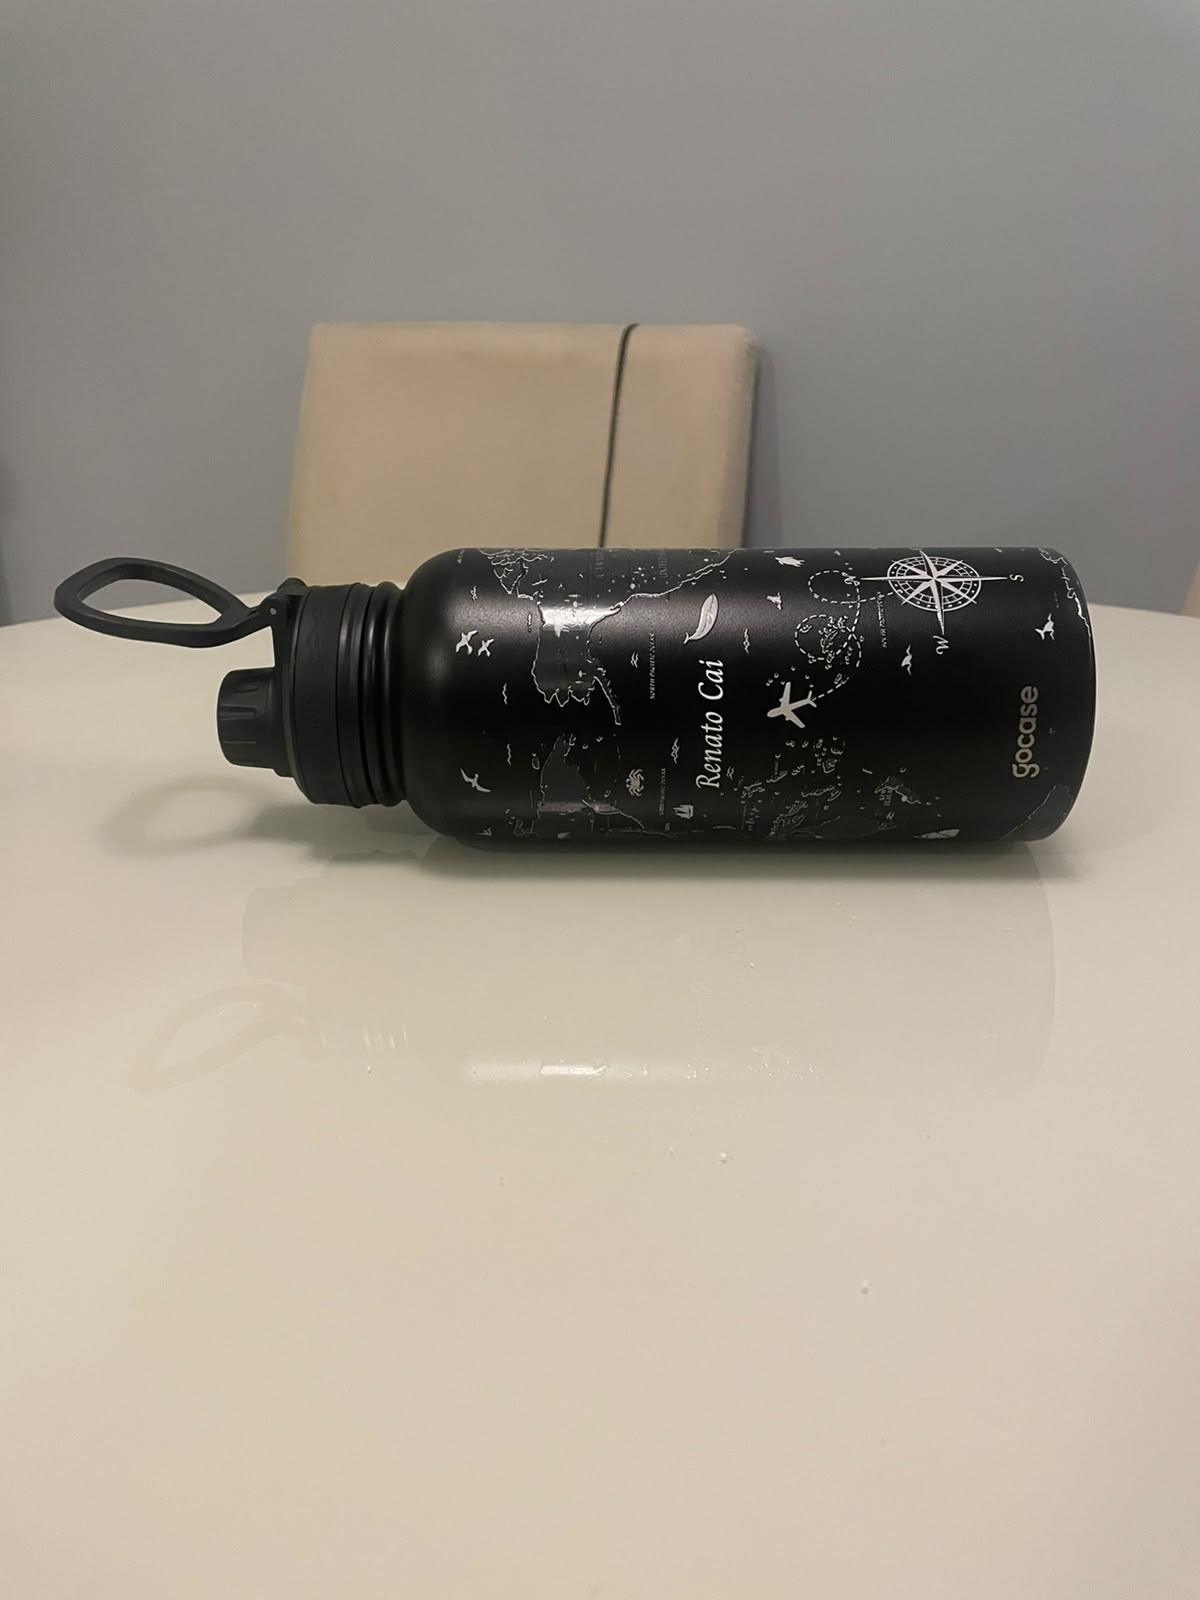

garrafa_042.jpeg


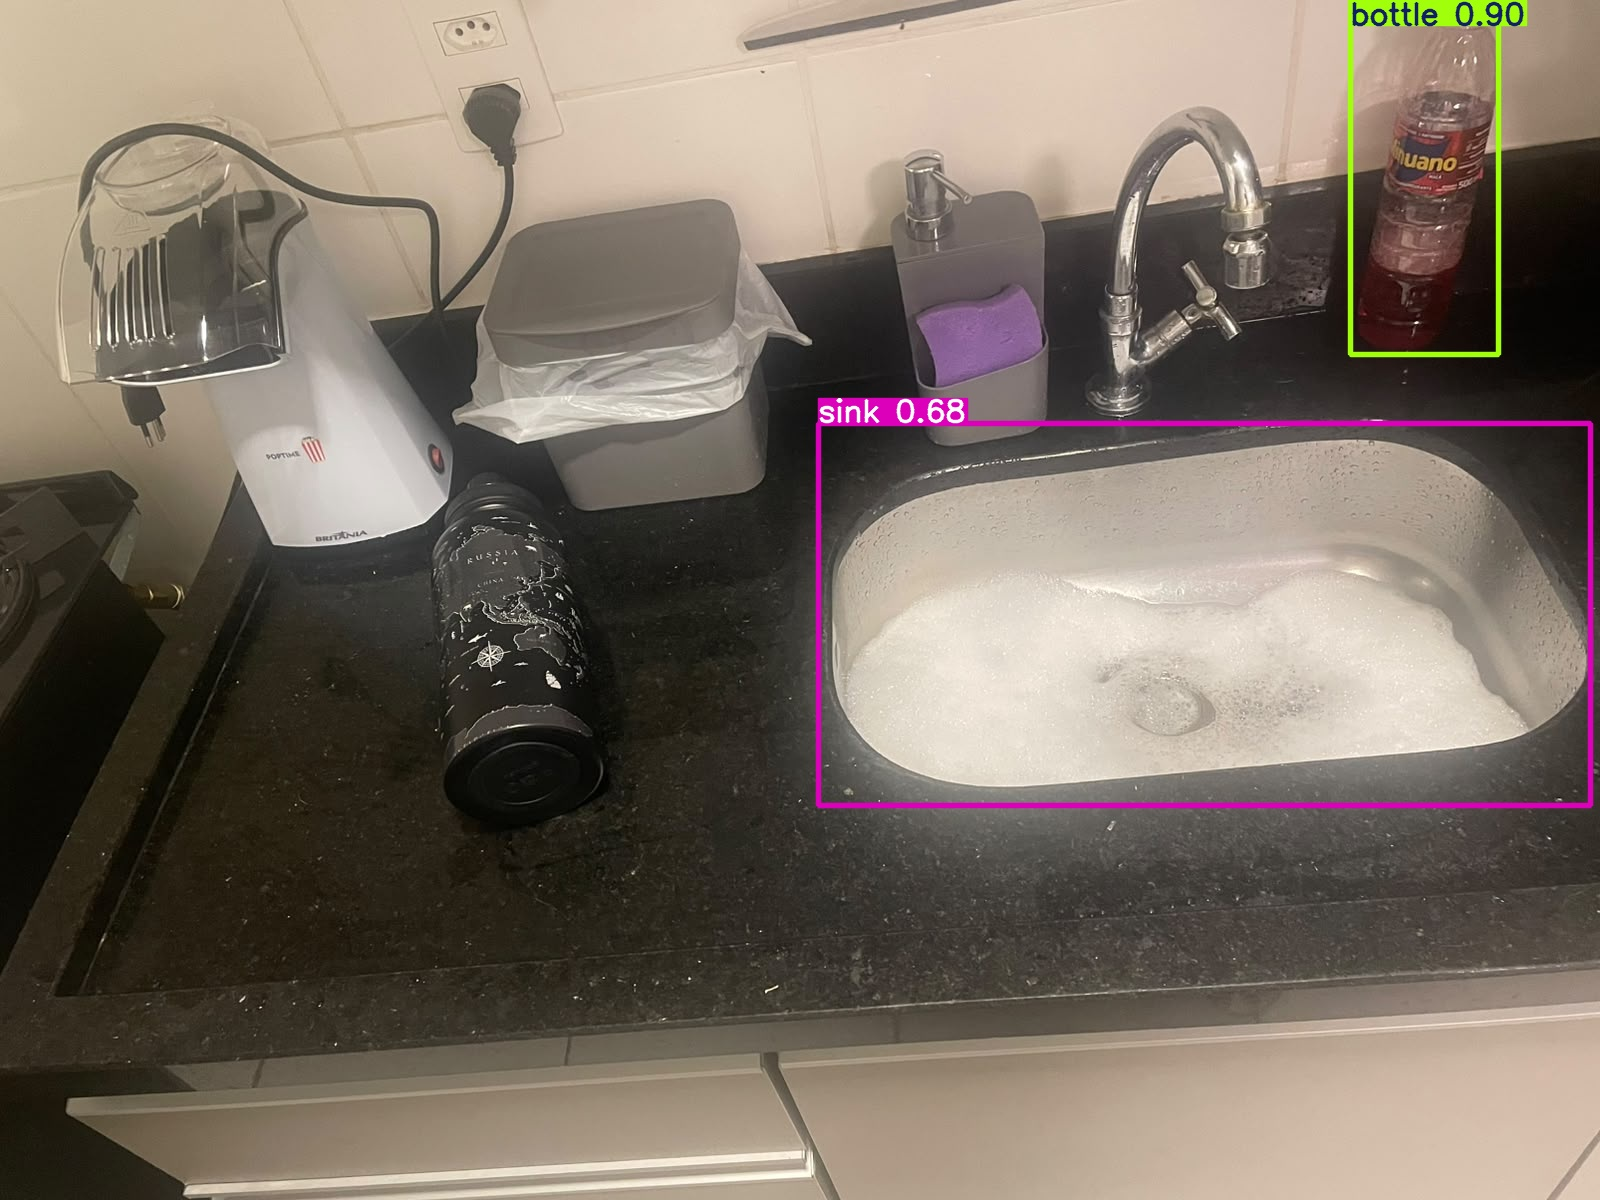

In [19]:

from IPython.display import display, Image
from pathlib import Path

# Define o diretório onde foram salvas as imagens processadas pelo YOLO padrão.
pasta = Path(
    '/content/drive/MyDrive/YOLO_Padrao_Resultados/yolo_padrao_deteccoes'
)

# Percorre os arquivos do diretório em ordem alfabética.
for arquivo in sorted(pasta.iterdir()):

    # Seleciona apenas os arquivos de imagem com extensões válidas.
    if arquivo.suffix.lower() in ('.jpg', '.jpeg', '.png'):

        # Exibe o nome do arquivo e a imagem com as detecções realizadas.
        print(arquivo.name)
        display(Image(filename=str(arquivo), width=500))


*A visualização das imagens processadas pelo YOLO padrão permitiu identificar limitações do modelo pré-treinado na detecção dos objetos específicos do projeto.*

*O **controle PS5 não foi reconhecido corretamente** em nenhuma das imagens, sendo classificado como `cell_phone` em um dos casos e não detectado nos demais. Esse comportamento está relacionado à ausência de uma classe específica para controles de videogame no conjunto de classes do COCO.*

*Para a **garrafa térmica**, o modelo apresentou resultados melhores, identificando o objeto como `bottle` em três imagens. Entretanto, também classificou incorretamente um tubo de detergente como garrafa, demonstrando dificuldade em diferenciar objetos com características visuais semelhantes.*

*Os resultados evidenciam que, embora o YOLO padrão consiga reconhecer algumas categorias genéricas, seu desempenho é limitado quando aplicado a objetos específicos que não estão representados diretamente em suas classes de treinamento.*

*Dessa forma, a análise visual reforça a importância da adaptação do YOLO ao dataset personalizado, permitindo reconhecer os controles PS5 e as garrafas térmicas de maneira mais adequada às necessidades do projeto.*

### Medindo tempo de inferência

*Nesta etapa, medimos o tempo de inferência do YOLO padrão, utilizando o modelo YOLOv5s com seus pesos originais, sem treinamento adicional.*

*O objetivo é avaliar o tempo necessário para processar as mesmas 10 imagens de teste utilizadas nos experimentos anteriores, permitindo comparar o desempenho computacional do modelo padrão com os modelos YOLO adaptáveis treinados por 30 e 60 épocas.*

*Para tornar a medição mais consistente, realizamos um aquecimento inicial da GPU e utilizamos a sincronização CUDA antes e depois do processamento. Os resultados são apresentados em tempo total e tempo médio por imagem, contribuindo para a análise da eficiência computacional das diferentes abordagens.*

In [20]:

import torch
import time
from pathlib import Path

# Carrega o YOLOv5s com os pesos originais pré-treinados no COCO.
modelo = torch.hub.load(
    '/content/yolov5',
    'yolov5s',
    pretrained=True,
    source='local'
)

# Transfere o modelo para a GPU e configura o modo de avaliação.
modelo.to('cuda')
modelo.eval()

# Define o diretório das imagens utilizadas no conjunto de teste.
pasta_teste = Path('/content/drive/MyDrive/dataset/images/test')

# Seleciona as imagens com extensões válidas, mantendo a ordem alfabética.
imagens = sorted([
    str(p) for p in pasta_teste.iterdir()
    if p.suffix.lower() in ('.jpg', '.jpeg', '.png')
])

# Realiza o aquecimento inicial da GPU para reduzir o impacto
# das primeiras execuções na medição de desempenho.
for imagem in imagens[:3]:
    modelo(imagem, size=640)

# Aguarda a conclusão das operações pendentes na GPU.
torch.cuda.synchronize()

# Inicia a contagem do tempo de inferência.
inicio = time.perf_counter()

# Processa individualmente todas as imagens do conjunto de teste.
for imagem in imagens:
    modelo(imagem, size=640)

# Garante que todas as operações da GPU foram concluídas.
torch.cuda.synchronize()

# Calcula o tempo total necessário para processar as imagens.
tempo_total = time.perf_counter() - inicio

# Apresenta o tempo total e o tempo médio de inferência por imagem.
print(f'Tempo total: {tempo_total:.3f} segundos')
print(f'Tempo médio: {tempo_total / len(imagens) * 1000:.2f} ms/imagem')


YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
Tempo total: 0.654 segundos
Tempo médio: 65.41 ms/imagem


### Conclusão YOLO Padrão

*O segundo experimento utilizou o modelo YOLOv5s com pesos pré-treinados no dataset COCO, sem realizar treinamento adicional com as imagens personalizadas do projeto.*

*O modelo foi aplicado às mesmas 10 imagens de teste utilizadas na Entrega 1, permitindo observar seu comportamento diante dos objetos selecionados: um controle de PlayStation 5 e uma garrafa térmica personalizada.*

*Durante a execução, o modelo não reconheceu corretamente o controle de PlayStation 5, classificando-o em uma imagem como `cell_phone` e não apresentando detecções correspondentes nas demais.*

*Em relação à garrafa térmica, o modelo identificou corretamente a categoria genérica `bottle` em três imagens. Entretanto, também classificou um tubo de detergente como `bottle`, demonstrando uma limitação na diferenciação entre objetos visualmente semelhantes.*

*O tempo total de inferência foi de `0,654 segundos` para as 10 imagens, com média de `65,41 milissegundos` por imagem.*

*Em comparação aos modelos personalizados da Entrega 1, o YOLO padrão apresentou menor adequação ao reconhecimento dos objetos específicos do projeto. Essa diferença está relacionada principalmente à ausência de treinamento com as classes personalizadas.*

*Por outro lado, o modelo padrão possui a vantagem de permitir a identificação imediata de diversas categorias de objetos, sem exigir a preparação de um dataset ou treinamento adicional.*

*Conclui-se que o YOLO padrão é uma alternativa prática para aplicações que envolvem classes já contempladas pelo COCO. Entretanto, para a identificação de objetos específicos, como os utilizados neste projeto, a personalização do modelo mostrou-se mais adequada.*

### ***- Entrega 2 parte 2 - Treinando uma CNN do zero ----------------------------------------***

### Importando as bibliotecas

*Nesta etapa, preparamos o ambiente para o desenvolvimento de uma Rede Neural Convolucional (CNN) utilizando TensorFlow e Keras, sem recorrer a modelos ou pesos pré-treinados.*

*O objetivo é importar as bibliotecas necessárias para construir, treinar e avaliar a CNN, além de verificar a versão do TensorFlow e a disponibilidade de uma GPU para acelerar o processamento.*

*Também utilizaremos bibliotecas auxiliares para manipulação dos dados, organização dos arquivos e medição dos tempos de treinamento e inferência, permitindo comparar posteriormente o desempenho da CNN com os modelos YOLO avaliados anteriormente.*

In [21]:

import tensorflow as tf
import numpy as np
import pandas as pd
import time

from pathlib import Path
from tensorflow.keras import layers, models

# Verifica a versão do TensorFlow utilizada no experimento.
print("TensorFlow:", tf.__version__)

# Identifica as GPUs disponíveis para acelerar o processamento da CNN.
print("GPUs disponíveis:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
GPUs disponíveis: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Configurando os caminhos

*Nesta etapa, configuramos os caminhos de acesso ao dataset e ao diretório de armazenamento dos resultados da CNN, mantendo os arquivos separados dos experimentos realizados com o YOLO.*

*Também definimos as duas classes que serão reconhecidas pela rede neural, além dos principais parâmetros de treinamento: resolução das imagens, quantidade de imagens processadas por lote (*batch size*) e número de épocas.*

*Essas configurações permitem padronizar o processamento das imagens e organizar os resultados, garantindo que a CNN utilize o mesmo conjunto de dados dos experimentos anteriores, porém com parâmetros adequados à tarefa de classificação.*

In [22]:

# Define o caminho do dataset utilizado nos experimentos anteriores.
DATASET = Path('/content/drive/MyDrive/dataset')

# Define o diretório onde serão armazenados os resultados da CNN.
CNN_RESULTADOS = Path(
    '/content/drive/MyDrive/CNN_Resultados'
)

# Cria o diretório de resultados, caso ainda não exista.
CNN_RESULTADOS.mkdir(
    parents=True,
    exist_ok=True
)

# Define os identificadores e nomes das classes utilizadas na classificação.
CLASSES = {
    0: 'controle_ps5',
    1: 'garrafa_termica'
}

# Define a resolução das imagens de entrada da CNN.
IMG_SIZE = (128, 128)

# Estabelece a quantidade de imagens processadas por lote.
BATCH_SIZE = 8

# Define o número de épocas utilizadas no treinamento.
EPOCHS = 30

# Verifica o acesso ao dataset e apresenta o diretório dos resultados.
print("Dataset encontrado:", DATASET.exists())
print("Resultados:", CNN_RESULTADOS)


Dataset encontrado: True
Resultados: /content/drive/MyDrive/CNN_Resultados


### Lendo as imagens e labels

*Nesta etapa, realizamos a leitura dos arquivos de imagem dos conjuntos de treinamento, validação e teste, identificando a classe correspondente a cada imagem.*

*A classificação é definida a partir do nome do arquivo, diferenciando os controles PS5 das garrafas térmicas. Em seguida, verificamos se cada imagem possui seu respectivo arquivo de anotação no formato YOLO e se a classe identificada está presente nesse arquivo.*

*Essa validação permite garantir a consistência entre as imagens e seus rótulos antes do treinamento da CNN. Ao final, organizamos os registros dos três conjuntos e apresentamos a quantidade de imagens disponíveis em cada um.*

*Diferentemente do YOLO, a CNN será utilizada para **classificar a imagem como um todo**, sem realizar a localização dos objetos por meio de caixas delimitadoras.*

In [23]:

# Define as extensões de imagem aceitas.
EXTENSOES = {'.jpg', '.jpeg', '.png'}

# Carrega os registros de um conjunto de dados (train, val ou test).
def carregar_registros(conjunto):
    registros = []

    # Define os diretórios das imagens e de suas anotações.
    pasta_imagens = DATASET / 'images' / conjunto
    pasta_labels = DATASET / 'labels' / conjunto

    # Percorre os arquivos de imagem em ordem alfabética.
    for imagem in sorted(pasta_imagens.iterdir()):

        # Ignora arquivos que não possuem uma extensão válida.
        if imagem.suffix.lower() not in EXTENSOES:
            continue

        # Obtém o nome do arquivo sem a extensão.
        nome = imagem.stem.lower()

        # Identifica a classe principal pelo prefixo do nome.
        if nome.startswith('controle'):
            classe = 0
        elif nome.startswith('garrafa'):
            classe = 1
        else:
            # Interrompe a execução caso a classe seja desconhecida.
            raise ValueError(
                f'Classe desconhecida: {imagem.name}'
            )

        # Localiza o arquivo de anotação correspondente à imagem.
        label = pasta_labels / f'{imagem.stem}.txt'

        # Verifica se o arquivo de anotação existe.
        if not label.exists():
            raise FileNotFoundError(label)

        # Lê os identificadores das classes presentes na anotação YOLO.
        classes_anotadas = [
            int(linha.split()[0])
            for linha in label.read_text().splitlines()
            if linha.strip()
        ]

        # Confirma que a classe identificada está presente na anotação.
        if classe not in classes_anotadas:
            raise ValueError(
                f'Classe principal não anotada: {imagem.name}'
            )

        # Armazena o caminho da imagem e sua classe para a CNN.
        registros.append((str(imagem), classe))

    return registros


# Carrega separadamente os conjuntos de treinamento, validação e teste.
treino = carregar_registros('train')
validacao = carregar_registros('val')
teste = carregar_registros('test')

# Apresenta a quantidade de imagens disponíveis em cada conjunto.
print('Treinamento:', len(treino))
print('Validação:', len(validacao))
print('Teste:', len(teste))


Treinamento: 74
Validação: 10
Teste: 10


### Preparando as imagens para a CNN

*Nesta etapa, realizamos o pré-processamento das imagens para adequá-las ao formato de entrada da Rede Neural Convolucional (CNN).*

*As imagens são carregadas, convertidas para três canais de cores (RGB), redimensionadas para 128 × 128 pixels e normalizadas para valores entre 0 e 1. Esse procedimento padroniza os dados de entrada e facilita o processo de treinamento da rede neural.*

*Em seguida, organizamos os conjuntos de treinamento, validação e teste utilizando a API `tf.data` do TensorFlow. Para o conjunto de treinamento, aplicamos o embaralhamento das imagens, enquanto os demais conjuntos mantêm sua ordem original.*

*Também utilizamos o processamento paralelo, a divisão em lotes (*batches*) e o pré-carregamento dos dados (*prefetch*) para otimizar a leitura das imagens e o desempenho durante o treinamento e a avaliação da CNN.*

In [25]:

# Prepara cada imagem e sua respectiva classe para utilização na CNN.
def preparar_imagem(caminho, classe):

    # Lê o arquivo de imagem a partir do caminho informado.
    imagem = tf.io.read_file(caminho)

    # Decodifica a imagem e garante a utilização de três canais RGB.
    imagem = tf.io.decode_image(
        imagem,
        channels=3,
        expand_animations=False
    )

    # Define o formato esperado da imagem: altura, largura e 3 canais.
    imagem.set_shape([None, None, 3])

    # Redimensiona a imagem para 128 x 128 pixels.
    imagem = tf.image.resize(
        imagem,
        IMG_SIZE
    )

    # Converte os pixels para float32 e normaliza os valores entre 0 e 1.
    imagem = tf.cast(imagem, tf.float32) / 255.0

    # Retorna a imagem processada e sua classe correspondente.
    return imagem, classe


# Cria um dataset TensorFlow a partir dos registros de imagens e classes.
def criar_dataset(registros, treinamento=False):

    # Separa os caminhos das imagens e seus respectivos rótulos.
    caminhos = [r[0] for r in registros]
    classes = [r[1] for r in registros]

    # Cria o dataset associando cada caminho à sua classe.
    ds = tf.data.Dataset.from_tensor_slices(
        (caminhos, classes)
    )

    # Embaralha os registros apenas durante o treinamento.
    if treinamento:
        ds = ds.shuffle(
            len(registros),
            seed=42
        )

    # Aplica o pré-processamento às imagens em paralelo.
    ds = ds.map(
        preparar_imagem,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Organiza as imagens em lotes de 8 amostras.
    ds = ds.batch(BATCH_SIZE)

    # Prepara antecipadamente os próximos lotes para otimizar a execução.
    return ds.prefetch(tf.data.AUTOTUNE)


# Cria o dataset de treinamento com embaralhamento.
ds_treino = criar_dataset(treino, treinamento=True)

# Cria o dataset de validação sem embaralhamento.
ds_val = criar_dataset(validacao)

# Cria o dataset de teste sem embaralhamento.
ds_teste = criar_dataset(teste)


### Criando o modelo

*Nesta etapa, construímos uma Rede Neural Convolucional (CNN) do zero, utilizando a API Keras do TensorFlow, para classificar as imagens entre as classes controle PS5 e garrafa térmica.*

*A arquitetura é composta por três camadas convolucionais, responsáveis pela extração progressiva de características visuais, intercaladas com camadas de *MaxPooling*, que reduzem as dimensões dos dados e o custo computacional.*

*Em seguida, utilizamos uma camada de *Global Average Pooling* para resumir as características extraídas, uma camada densa para aprender padrões de classificação e uma camada de *Dropout* para ajudar a reduzir o risco de sobreajuste (*overfitting*).*

*A camada de saída utiliza a função *softmax* para produzir as probabilidades das duas classes. Por fim, configuramos o treinamento com o otimizador Adam, a função de perda *sparse categorical crossentropy* e a métrica de acurácia.*

*Diferentemente dos experimentos com YOLO, **a CNN não utiliza pesos pré-treinados**, permitindo avaliar o aprendizado de uma rede neural construída especificamente para este experimento.*

In [26]:

# Define uma semente aleatória para favorecer a reprodutibilidade.
tf.keras.utils.set_random_seed(42)

# Constrói a CNN utilizando uma arquitetura sequencial.
modelo_cnn = models.Sequential([

    # Define a entrada com imagens RGB de 128 x 128 pixels.
    layers.Input(shape=(128, 128, 3)),

    # Primeiro bloco convolucional: extrai características visuais iniciais.
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Segundo bloco: aprende características visuais mais complexas.
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Terceiro bloco: extrai padrões de maior complexidade.
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Resume os mapas de características em um vetor.
    layers.GlobalAveragePooling2D(),

    # Combina as características extraídas para realizar a classificação.
    layers.Dense(64, activation='relu'),

    # Desativa aleatoriamente 30% das unidades durante o treinamento,
    # ajudando a reduzir o risco de overfitting.
    layers.Dropout(0.3),

    # Produz as probabilidades das duas classes utilizando softmax.
    layers.Dense(2, activation='softmax')
])

# Configura o processo de treinamento da CNN.
modelo_cnn.compile(

    # Utiliza o otimizador Adam com taxa de aprendizado de 0.001.
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    # Define a função de perda para classificação multiclasse
    # com rótulos representados por números inteiros (0 e 1).
    loss='sparse_categorical_crossentropy',

    # Utiliza a acurácia para acompanhar o desempenho do modelo.
    metrics=['accuracy']
)

# Exibe a arquitetura, os formatos das saídas e a quantidade de parâmetros.
modelo_cnn.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,634 (397.01 KB)

 Trainable params: 101,634 (397.01 KB)

 Non-trainable params: 0 (0.00 B)

### Executando o treinamento

*Nesta etapa, realizamos o treinamento da Rede Neural Convolucional (CNN) construída do zero, utilizando as imagens do conjunto de treinamento e os respectivos rótulos.*

*O modelo é treinado durante 30 épocas, utilizando o conjunto de validação para acompanhar seu desempenho ao longo do processo. Durante a execução, são apresentados os valores de perda (*loss*) e acurácia (*accuracy*) dos conjuntos de treinamento e validação, permitindo observar a evolução do aprendizado e identificar possíveis sinais de sobreajuste (*overfitting*).*

*Também registramos o tempo total de treinamento, em segundos e minutos, para comparar posteriormente o custo computacional da CNN com os modelos YOLO avaliados anteriormente.*

In [27]:


# Registra o instante inicial para medir o tempo de treinamento.
inicio_cnn = time.perf_counter()

# Executa o treinamento da CNN utilizando as imagens preparadas.
historico = modelo_cnn.fit(

    # Conjunto de imagens e rótulos utilizado para treinar o modelo.
    ds_treino,

    # Conjunto utilizado para acompanhar o desempenho a cada época.
    validation_data=ds_val,

    # Define a quantidade de épocas de treinamento (30).
    epochs=EPOCHS,

    # Exibe o progresso e as métricas durante o treinamento.
    verbose=1
)

# Calcula o tempo total necessário para concluir o treinamento.
tempo_cnn = time.perf_counter() - inicio_cnn

# Apresenta o tempo de treinamento em segundos e minutos.
print(f'Tempo de treinamento: {tempo_cnn:.2f} segundos')
print(f'Tempo de treinamento: {tempo_cnn / 60:.2f} minutos')



Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.4189 - loss: 0.7045 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step - accuracy: 0.5270 - loss: 0.6906 - val_accuracy: 0.5000 - val_loss: 0.6927
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step - accuracy: 0.5135 - loss: 0.6951 - val_accuracy: 0.5000 - val_loss: 0.6926
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - accuracy: 0.5135 - loss: 0.6907 - val_accuracy: 0.5000 - val_loss: 0.6875
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.5135 - loss: 0.6926 - val_accuracy: 0.5000 - val_loss: 0.6840
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 0.5135 - loss: 0.6772 - val_accuracy: 0.5000 - val_loss: 0.6720
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - accuracy: 0.5541 - loss: 0.6667 - val_accuracy: 0.6000 - val_loss: 0.6625
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - accuracy: 0.6351 - loss: 0.6487 - val_accuracy: 0.80

### Gerando gráficos

*Nesta etapa, geramos gráficos para visualizar a evolução do desempenho da CNN durante as 30 épocas de treinamento, utilizando as métricas armazenadas no histórico do modelo.*

*O primeiro gráfico apresenta a evolução da acurácia (*accuracy*) nos conjuntos de treinamento e validação, permitindo acompanhar a capacidade da rede neural de classificar corretamente as imagens.*

*O segundo gráfico apresenta a evolução da função de perda (*loss*), indicando o comportamento dos erros do modelo ao longo do treinamento.*

*A comparação entre as curvas de treinamento e validação permite analisar a evolução do aprendizado, verificar a estabilidade do modelo e identificar possíveis sinais de sobreajuste (*overfitting*) ou aprendizado insuficiente (*underfitting*).*

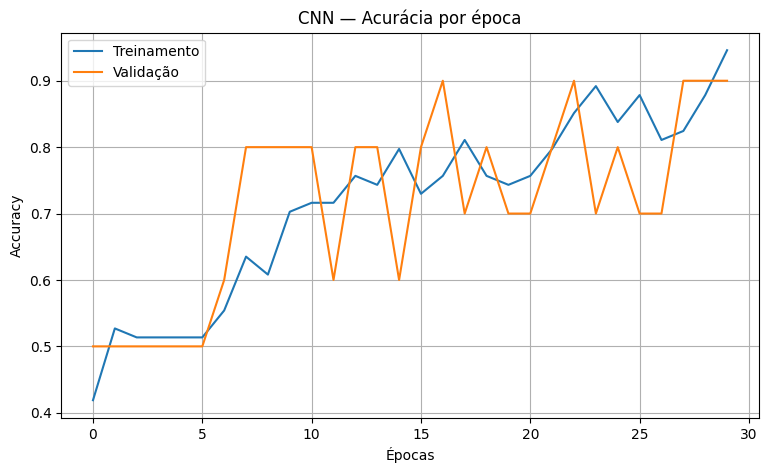

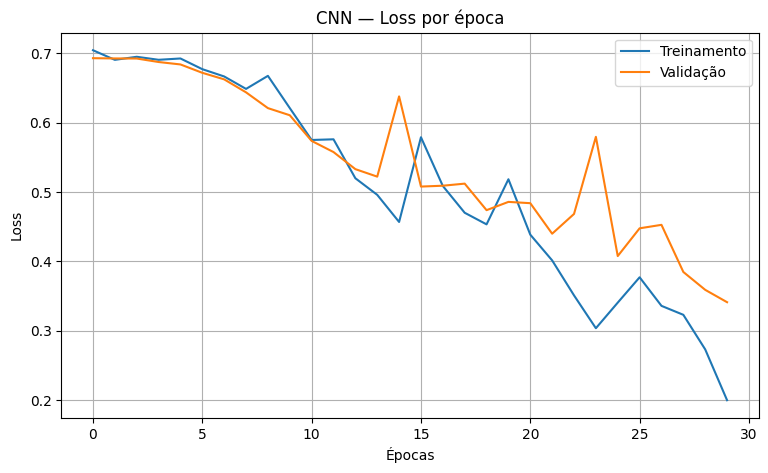

In [28]:

import matplotlib.pyplot as plt

# Cria a figura para visualizar a evolução da acurácia.
plt.figure(figsize=(9, 5))

# Apresenta a acurácia obtida durante o treinamento.
plt.plot(
    historico.history['accuracy'],
    label='Treinamento'
)

# Apresenta a acurácia obtida no conjunto de validação.
plt.plot(
    historico.history['val_accuracy'],
    label='Validação'
)

# Configura o título, os eixos e os elementos visuais do gráfico.
plt.title('CNN — Acurácia por época')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Exibe o gráfico de evolução da acurácia.
plt.show()

# Cria a figura para visualizar a evolução da função de perda.
plt.figure(figsize=(9, 5))

# Apresenta os valores de perda durante o treinamento.
plt.plot(
    historico.history['loss'],
    label='Treinamento'
)

# Apresenta os valores de perda no conjunto de validação.
plt.plot(
    historico.history['val_loss'],
    label='Validação'
)

# Configura o título, os eixos e os elementos visuais do gráfico.
plt.title('CNN — Loss por época')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Exibe o gráfico de evolução da função de perda.
plt.show()


*A geração dos gráficos de acurácia (*accuracy*) e perda (*loss*) permitiu acompanhar a evolução do aprendizado da CNN ao longo das 30 épocas de treinamento.*

*O gráfico de acurácia permite observar a capacidade do modelo de classificar corretamente as imagens, enquanto o gráfico de perda demonstra a evolução dos erros durante o treinamento. A comparação entre as curvas de treinamento e validação é importante para identificar possíveis diferenças no desempenho e sinais de sobreajuste (*overfitting*).*

*Considerando que a CNN alcançou **90% de acurácia no conjunto de teste**, os resultados finais indicam que o modelo conseguiu aprender características relevantes para diferenciar os controles PS5 das garrafas térmicas, mesmo utilizando uma arquitetura simples e um conjunto reduzido de imagens.*

*Entretanto, como o conjunto de validação possui apenas 10 imagens, as métricas podem apresentar oscilações significativas entre as épocas. Dessa forma, a interpretação das curvas deve considerar essa limitação.*

*Os gráficos complementam a avaliação quantitativa da CNN, permitindo analisar seu processo de aprendizado e relacioná-lo ao desempenho obtido no conjunto de teste.*

### Salvando arquivos

*Nesta etapa, salvamos o modelo CNN treinado e os principais registros do processo de treinamento no Google Drive, garantindo a preservação dos resultados obtidos.*

*O modelo é armazenado no formato nativo do Keras (`.keras`), permitindo seu carregamento posterior sem a necessidade de realizar um novo treinamento.*

*Também exportamos o histórico das métricas de treinamento e validação para um arquivo CSV, possibilitando consultar e analisar a evolução da acurácia e da perda ao longo das 30 épocas.*

*Por fim, registramos o tempo total de treinamento em um arquivo de texto, mantendo as informações necessárias para a comparação de desempenho computacional entre a CNN e os modelos YOLO avaliados anteriormente.*

In [29]:

import pandas as pd

# Salva o modelo CNN treinado no formato nativo do Keras.
# O arquivo permite carregar o modelo posteriormente sem treiná-lo novamente.
modelo_cnn.save(
    str(CNN_RESULTADOS / 'cnn_30_epocas.keras')
)

# Converte o histórico de treinamento em uma tabela e exporta para CSV.
# O arquivo contém as métricas de loss e accuracy de cada época,
# tanto para treinamento quanto para validação.
pd.DataFrame(historico.history).to_csv(
    CNN_RESULTADOS / 'historico_30_epocas.csv',
    index=False
)

# Cria um arquivo de texto para registrar o tempo total de treinamento.
with open(CNN_RESULTADOS / 'tempo_treinamento.txt', 'w') as f:

    # Registra o tempo em segundos.
    f.write(f'{tempo_cnn:.4f} segundos\n')

    # Registra o mesmo tempo convertido para minutos.
    f.write(f'{tempo_cnn / 60:.4f} minutos\n')

# Confirma a conclusão do salvamento dos arquivos.
print('Modelo e resultados salvos no Google Drive!')


Modelo e resultados salvos no Google Drive!


### Calculando a acurácia no teste

*Nesta etapa, avaliamos o desempenho da CNN utilizando o conjunto de teste, composto por 10 imagens que não foram utilizadas durante o treinamento ou a validação do modelo.*

*O objetivo é verificar a capacidade de generalização da rede neural, calculando a acurácia (*accuracy*) e a função de perda (*loss*) sobre imagens não utilizadas no aprendizado.*

*A acurácia representa a proporção de imagens classificadas corretamente, enquanto a perda indica o erro calculado pela função *sparse categorical crossentropy*.*

*Essa avaliação permite verificar o desempenho final da CNN na classificação dos controles PS5 e das garrafas térmicas, fornecendo resultados para a análise comparativa com os experimentos anteriores.*

In [30]:

# Avalia o desempenho da CNN utilizando o conjunto de teste.
# Retorna a perda (loss) e a acurácia (accuracy) do modelo.
loss_teste, accuracy_teste = modelo_cnn.evaluate(
    ds_teste,

    # Exibe o progresso da avaliação.
    verbose=1
)

# Apresenta o valor da função de perda no conjunto de teste.
print(f'Loss no teste: {loss_teste:.4f}')

# Converte a acurácia para porcentagem e apresenta o resultado.
print(f'Acurácia no teste: {accuracy_teste * 100:.2f}%')


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.9000 - loss: 0.4172
Loss no teste: 0.4172
Acurácia no teste: 90.00%


*A avaliação da CNN no conjunto de teste apresentou **90% de acurácia** e **loss de 0,4172**, demonstrando um desempenho positivo na classificação das duas classes do projeto: controle PS5 e garrafa térmica.*

*Das 10 imagens utilizadas no teste, o modelo classificou corretamente 9, cometendo apenas um erro. Esse resultado indica que a CNN conseguiu aprender características visuais relevantes para diferenciar os objetos, mesmo tendo sido treinada do zero, sem utilizar pesos pré-treinados.*

*O resultado também demonstra que uma arquitetura relativamente simples, com 101.634 parâmetros treináveis, foi capaz de apresentar boa capacidade de classificação no conjunto avaliado.*

*Entretanto, considerando o tamanho reduzido do conjunto de teste, cada erro representa uma variação de 10 pontos percentuais na acurácia. Portanto, os resultados são promissores, mas não garantem o mesmo desempenho em imagens mais diversificadas.*

*A avaliação confirma a viabilidade da CNN para a tarefa de classificação proposta, servindo como referência para a comparação com os modelos YOLO, que realizam uma tarefa mais complexa de detecção e localização de objetos.*

### Calculando precision, recall e F1-score

*Nesta etapa, calculamos as métricas de Precision, Recall e F1-score para avaliar o desempenho da CNN individualmente em cada uma das duas classes: controle PS5 e garrafa térmica.*

*Inicialmente, utilizamos o modelo treinado para gerar as probabilidades de classificação das imagens do conjunto de teste. Em seguida, identificamos a classe com maior probabilidade para cada imagem e comparamos as predições com os rótulos reais.*

*Com a função `classification_report` da biblioteca Scikit-learn, geramos um relatório contendo Precision, Recall, F1-score e a quantidade de imagens avaliadas por classe (*support*).*

*Essa análise complementa a acurácia geral, permitindo identificar diferenças no desempenho da CNN entre as duas categorias e compreender melhor os erros de classificação.*

In [31]:

from sklearn.metrics import classification_report
import numpy as np

# Executa a CNN sobre as imagens de teste.
# Retorna as probabilidades previstas para cada uma das duas classes.
probabilidades = modelo_cnn.predict(
    ds_teste,
    verbose=0
)

# Seleciona a classe com maior probabilidade para cada imagem.
# Classe 0: controle_ps5 | Classe 1: garrafa_termica.
predicoes = np.argmax(
    probabilidades,
    axis=1
)

# Recupera os rótulos reais das imagens do conjunto de teste.
classes_reais = np.array([
    classe for _, classe in teste
])

# Gera o relatório comparando as classes reais com as predições.
print(
    classification_report(
        classes_reais,
        predicoes,

        # Define os identificadores das classes avaliadas.
        labels=[0, 1],

        # Define os nomes apresentados no relatório.
        target_names=[
            'controle_ps5',
            'garrafa_termica'
        ],

        # Apresenta as métricas com três casas decimais.
        digits=3,

        # Evita avisos e divisões indefinidas quando uma métrica
        # não puder ser calculada.
        zero_division=0
    )
)


                 precision    recall  f1-score   support

   controle_ps5      1.000     0.800     0.889         5
garrafa_termica      0.833     1.000     0.909         5

       accuracy                          0.900        10
      macro avg      0.917     0.900     0.899        10
   weighted avg      0.917     0.900     0.899        10



*A avaliação das métricas Precision, Recall e F1-score demonstrou um desempenho positivo da CNN na classificação dos controles PS5 e das garrafas térmicas.*

*Para a classe **controle PS5**, o modelo alcançou Precision de **100%**, Recall de **80%** e F1-score de **88,9%**. Esses resultados indicam que todas as imagens classificadas como controle estavam corretas, porém um dos cinco controles foi identificado incorretamente como garrafa térmica.*

*Já para a classe **garrafa térmica**, a CNN apresentou Precision de **83,3%**, Recall de **100%** e F1-score de **90,9%**. O modelo identificou corretamente todas as cinco garrafas, mas também classificou um controle PS5 como garrafa térmica, reduzindo sua precisão.*

*Considerando as duas classes, o modelo obteve **F1-score macro de 89,9%**, demonstrando um desempenho relativamente equilibrado entre Precision e Recall.*

*Os resultados complementam a acurácia geral de 90% e evidenciam que a principal dificuldade da CNN ocorreu na identificação de um controle PS5.*

### Gerando matriz de confusão

*Nesta etapa, geramos a matriz de confusão da CNN para visualizar a distribuição dos acertos e erros de classificação no conjunto de teste.*

*A matriz compara as classes reais das imagens com as classes previstas pelo modelo, permitindo identificar quantos controles PS5 e garrafas térmicas foram classificados corretamente e quantos foram confundidos com a outra categoria.*

*Essa visualização complementa as métricas de acurácia, Precision, Recall e F1-score, facilitando a identificação dos tipos de erro cometidos pela rede neural e a análise de seu desempenho em cada classe.*

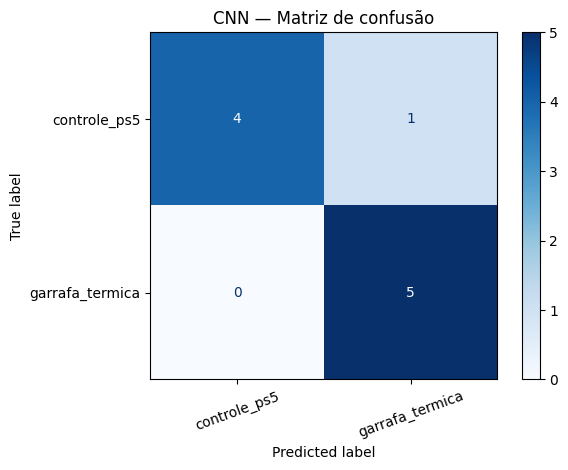

In [32]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calcula a matriz comparando as classes reais com as predições.
# Define a ordem das classes: 0 (controle) e 1 (garrafa).
matriz = confusion_matrix(
    classes_reais,
    predicoes,
    labels=[0, 1]
)

# Configura a visualização da matriz com os nomes das classes.
visualizacao = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=[
        'controle_ps5',
        'garrafa_termica'
    ]
)

# Gera o gráfico utilizando a escala de cores azul.
# Os valores são apresentados como números inteiros.
visualizacao.plot(
    cmap='Blues',
    values_format='d'
)

# Define o título e ajusta a apresentação do gráfico.
plt.title('CNN — Matriz de confusão')
plt.xticks(rotation=20)
plt.tight_layout()

# Exibe a matriz de confusão.
plt.show()


*A matriz de confusão da CNN demonstrou um desempenho positivo na classificação das duas classes do projeto, com **9 acertos em 10 imagens avaliadas**, confirmando a acurácia de 90% obtida anteriormente.*

*Para a classe **controle PS5**, o modelo classificou corretamente 4 das 5 imagens, enquanto 1 controle foi identificado incorretamente como garrafa térmica. Já para a classe **garrafa térmica**, todas as 5 imagens foram classificadas corretamente, sem apresentar erros.*

*A análise evidencia que a principal dificuldade da CNN ocorreu na identificação de um controle PS5, enquanto a classe garrafa térmica apresentou melhor desempenho em termos de Recall.*

*Os resultados indicam que a rede neural conseguiu aprender características visuais relevantes para diferenciar os dois objetos, mesmo utilizando uma arquitetura construída do zero e um conjunto reduzido de treinamento.*

### Medindo tempo de inferência

*Nesta etapa, medimos o tempo de inferência da CNN treinada do zero, utilizando as mesmas 10 imagens do conjunto de teste empregadas nos experimentos anteriores.*

*Inicialmente, carregamos as imagens já pré-processadas para a memória, evitando que a leitura dos arquivos interfira na medição. Em seguida, realizamos um aquecimento do modelo para reduzir o impacto das primeiras execuções no tempo registrado.*

*Após o aquecimento, processamos individualmente cada imagem e calculamos o tempo total de inferência e o tempo médio por imagem, utilizando a função `perf_counter`.*

*O objetivo é avaliar a eficiência computacional da CNN durante a classificação e comparar seu desempenho com os modelos YOLO padrão e adaptáveis, considerando as diferenças entre as arquiteturas e as tarefas executadas.*

In [33]:

import time
import numpy as np

# Carrega todas as imagens de teste já pré-processadas para a memória.
# Isso evita incluir o tempo de leitura dos arquivos na medição.
imagens_teste = np.concatenate(
    [imagens.numpy() for imagens, _ in ds_teste],
    axis=0
)

# Realiza três execuções iniciais para aquecer o modelo
# e reduzir o impacto da inicialização na medição.
for _ in range(3):
    modelo_cnn(
        imagens_teste[:1],
        training=False
    ).numpy()

# Registra o instante inicial da medição.
inicio = time.perf_counter()

# Executa a inferência individualmente para cada imagem de teste.
for imagem in imagens_teste:
    modelo_cnn(

        # Adiciona a dimensão do lote exigida pela CNN.
        imagem[np.newaxis, ...],

        # Desativa comportamentos exclusivos do treinamento,
        # como o Dropout.
        training=False
    ).numpy()

# Calcula o tempo total necessário para classificar as imagens.
tempo_total_inferencia = time.perf_counter() - inicio

# Calcula o tempo médio por imagem e converte para milissegundos.
tempo_medio_inferencia = (
    tempo_total_inferencia / len(imagens_teste) * 1000
)

# Apresenta o tempo total de inferência em segundos.
print(
    f'Tempo total: {tempo_total_inferencia:.3f} segundos'
)

# Apresenta o tempo médio de inferência por imagem.
print(
    f'Tempo médio: {tempo_medio_inferencia:.2f} ms/imagem'
)


Tempo total: 0.401 segundos
Tempo médio: 40.10 ms/imagem


### Salvando métricas finais

*Nesta etapa, consolidamos e salvamos as principais métricas obtidas durante o treinamento e a avaliação da CNN em um arquivo JSON.*

*O arquivo reúne informações sobre a configuração do experimento, a quantidade de imagens utilizadas nos conjuntos de treinamento, validação e teste, os resultados de acurácia e perda, além dos tempos de treinamento e inferência.*

*O objetivo é preservar os resultados de forma estruturada, facilitando sua consulta e utilização na análise comparativa entre a CNN, o YOLO padrão e os modelos YOLO adaptáveis.*

*As métricas são armazenadas no Google Drive, permitindo sua recuperação em sessões futuras sem a necessidade de executar novamente os experimentos.*

In [34]:

import json

# Organiza as principais informações e métricas do experimento.
metricas_cnn = {

    # Identifica o modelo utilizado no experimento.
    'modelo': 'CNN do zero',

    # Registra a quantidade de épocas de treinamento.
    'epocas': 30,

    # Registra a quantidade de imagens em cada conjunto.
    'imagens_treino': len(treino),
    'imagens_validacao': len(validacao),
    'imagens_teste': len(teste),

    # Armazena as métricas obtidas na avaliação do conjunto de teste.
    'accuracy_teste': float(accuracy_teste),
    'loss_teste': float(loss_teste),

    # Registra o tempo total de treinamento em segundos.
    'tempo_treinamento_segundos': float(tempo_cnn),

    # Registra o tempo total de inferência em segundos.
    'tempo_inferencia_total_segundos': float(
        tempo_total_inferencia
    ),

    # Registra o tempo médio de inferência por imagem em milissegundos.
    'tempo_inferencia_medio_ms': float(
        tempo_medio_inferencia
    )
}

# Cria o arquivo JSON no diretório de resultados da CNN.
with open(
    CNN_RESULTADOS / 'metricas_cnn.json',
    'w'
) as arquivo:

    # Salva as métricas em formato JSON.
    # O parâmetro indent=4 organiza o conteúdo para facilitar a leitura.
    json.dump(
        metricas_cnn,
        arquivo,
        indent=4
    )

# Confirma que o arquivo foi salvo.
print('Métricas salvas com sucesso!')


Métricas salvas com sucesso!


### Conclusão geral

*A segunda entrega teve como objetivo comparar três abordagens de visão computacional: YOLO adaptável, YOLO padrão e uma rede neural convolucional (CNN) treinada do zero. Os experimentos utilizaram um conjunto de 94 imagens, dividido em 74 imagens para treinamento, 10 para validação e 10 para teste, envolvendo as classes controle PS5 e garrafa térmica.*

*O YOLO adaptável foi treinado por 30 e 60 épocas utilizando pesos pré-treinados do YOLOv5s. No conjunto de teste, os modelos alcançaram mAP50 de `88,8% e 87,9%`, respectivamente. O treinamento de 60 épocas apresentou melhor mAP50-95, passando de `51,1% para 63,5%`, indicando melhor desempenho na localização dos objetos em critérios mais rigorosos de sobreposição das caixas delimitadoras.*

*O YOLO padrão, utilizado sem treinamento adicional, apresentou limitações no reconhecimento dos objetos específicos. O controle PS5 foi identificado incorretamente como telefone celular em uma imagem e não foi detectado nas demais. A garrafa térmica foi reconhecida como `bottle` em três imagens, mas também houve a classificação de um tubo de detergente nessa categoria. Esses resultados evidenciam a diferença entre a identificação de classes genéricas e o reconhecimento de objetos personalizados.*

*A CNN foi desenvolvida com TensorFlow/Keras, sem utilizar pesos pré-treinados, e treinada durante 30 épocas. O tempo total de treinamento foi de 65,35 segundos. No conjunto de teste, alcançou `90% de acurácia`, com nove imagens classificadas corretamente e uma classificação incorreta. A matriz de confusão demonstrou que a rede reconheceu corretamente todas as imagens de garrafa térmica, mas confundiu uma imagem de controle PS5 com a classe garrafa térmica.*

*Em relação ao tempo de inferência, foram registrados valores médios de `47,56 ms` para o YOLO adaptável de 30 épocas, `50,76 ms` para o modelo de 60 épocas, `65,41 ms` para o YOLO padrão e `40,10 ms` para a CNN. Entretanto, como os procedimentos de medição não foram completamente equivalentes, esses resultados devem ser interpretados como indicativos.*

*A comparação também demonstrou que as arquiteturas atendem a objetivos distintos. O YOLO é adequado para aplicações que precisam identificar a posição dos objetos nas imagens, enquanto a CNN desenvolvida neste projeto realiza a classificação da imagem como um todo. Consequentemente, a acurácia da CNN não pode ser comparada diretamente ao mAP do YOLO.*

*Conclui-se que a personalização do YOLO foi importante para reconhecer os objetos específicos do projeto, enquanto a CNN demonstrou ser uma alternativa viável para a classificação de imagens, mesmo com uma quantidade reduzida de dados. A escolha da abordagem mais adequada depende dos requisitos da aplicação, especialmente da necessidade de localizar objetos, da disponibilidade de dados anotados e do custo computacional de treinamento e execução.*